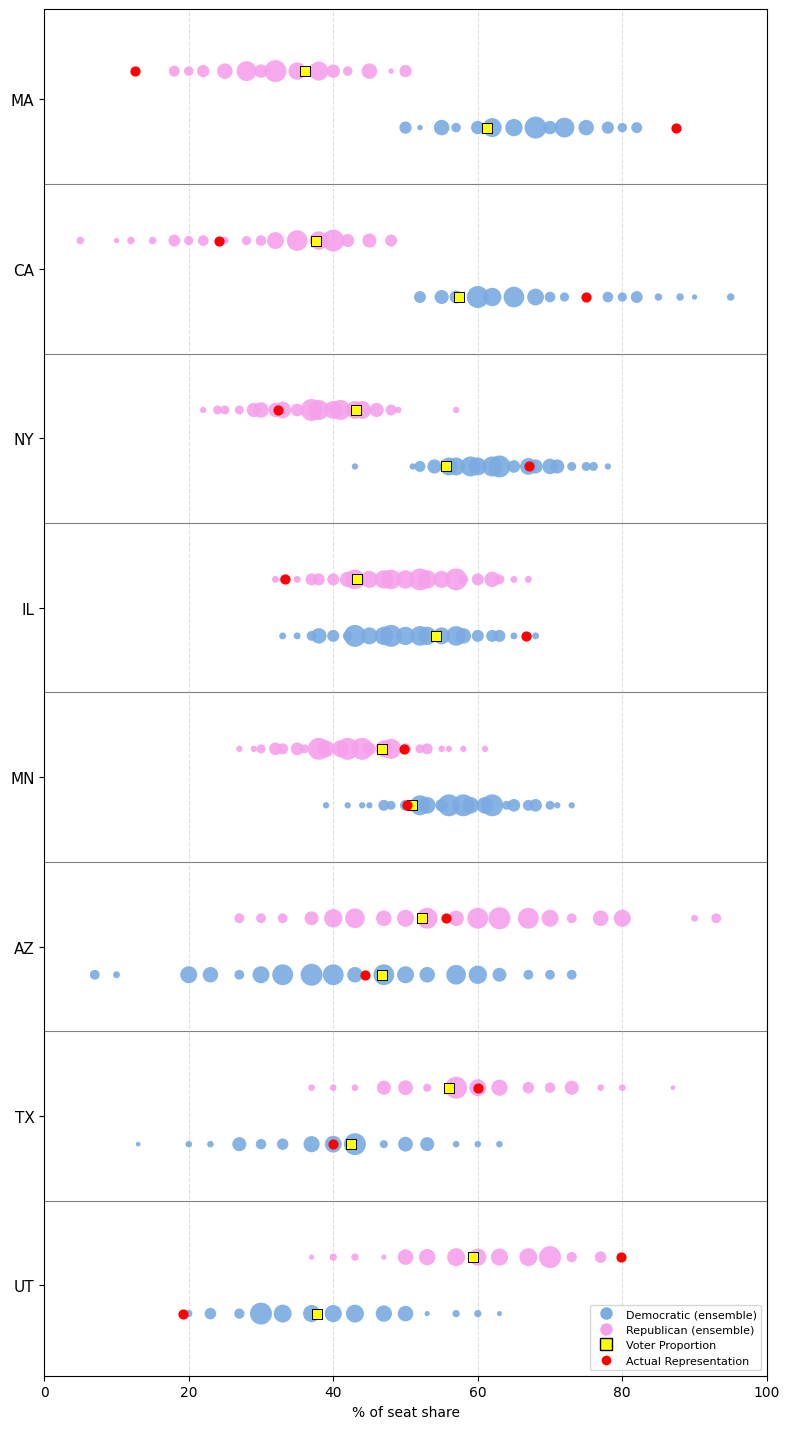

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

states = ['MA', 'CA', 'NY', 'IL', 'MN', 'AZ', 'TX', 'UT']  # add your states
party_list = ["dem", "rep"]
colors = {"dem": "#7AABE1", "rep": "#F5A0EB"}

state_props = {}
status_quo  = {}
seat_shares = {}
seat_shares_smd = {}
election_margins_rcv = {}
election_margins_smd = {}

for st in states:
    with open(f"/Users/zhaoyiran/Desktop/Data/{st}/{st}_state_info_p.pkl", "rb") as f:
        info = pickle.load(f)
    state_props[st] = info["state_props"]
    status_quo[st]  = info["status_quo"]
    with open(f"/Users/zhaoyiran/Desktop/Data/{st}/{st}_sl_seat_shares_p.pkl", "rb") as f:
        seat_shares[st] = pickle.load(f)
    with open(f"/Users/zhaoyiran/Desktop/Data/{st}/{st}_sl_seat_shares_smd.pkl", "rb") as f:
        seat_shares_smd[st] = pickle.load(f)
    with open(f"/Users/zhaoyiran/Desktop/Data/{st}/{st}_election_margins_rcv.pkl", "rb") as f:
        election_margins_rcv[st] = pickle.load(f)
    with open(f"/Users/zhaoyiran/Desktop/Data/{st}/{st}_election_margins_smd.pkl", "rb") as f:
        election_margins_smd[st] = pickle.load(f)

n_groups   = len(party_list)
gap        = 1                  # blank rows between states
row_height = n_groups + gap

MAX_BUBBLE_AREA = 250

fig, ax = plt.subplots(figsize=(8, len(states) * 1.8))

ytick_pos    = []
ytick_labels = []

for i, st in enumerate(states):
    base_y = (len(states) - 1 - i) * row_height

    for j, r in enumerate(party_list):
        y = base_y + j
        values = seat_shares[st][r]
        uniq, counts = np.unique(np.round(values, 2), return_counts=True)
        freqs = counts / counts.max()

        ax.scatter(uniq * 100, np.full_like(uniq, y, dtype=float),
                   s=freqs * MAX_BUBBLE_AREA,
                   color=colors[r], alpha=0.9, edgecolors="none", zorder=2)

        # Yellow square: voter proportion
        ax.scatter(state_props[st][r] * 100, y,
                   s=60, color="yellow", marker="s",
                   edgecolors="black", linewidths=0.7, zorder=3)

        # Red dot: status quo
        ax.scatter(status_quo[st][r] * 100, y,
                   s=40, color="red", marker="o", zorder=3)

    # State label at middle of its band
    mid_y = base_y + (n_groups - 1) / 2
    ytick_pos.append(mid_y)
    ytick_labels.append(st)

    # Separating line between this state and the next
    if i < len(states) - 1:
        sep_y = base_y - (gap + 1) / 2
        ax.axhline(sep_y, color="gray", linestyle="-", linewidth=0.8, zorder=1)

ax.set_xlim(0, 100)
ax.set_xlabel("% of seat share")
ax.set_yticks(ytick_pos)
ax.set_yticklabels(ytick_labels, fontsize=11)
ax.grid(axis="x", linestyle="--", alpha=0.4)

# Legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#7AABE1", markersize=10, label="Democratic (ensemble)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#F5A0EB", markersize=10, label="Republican (ensemble)"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="yellow", markeredgecolor="black", markersize=8, label="Voter Proportion"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="red", markersize=8, label="Actual Representation"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


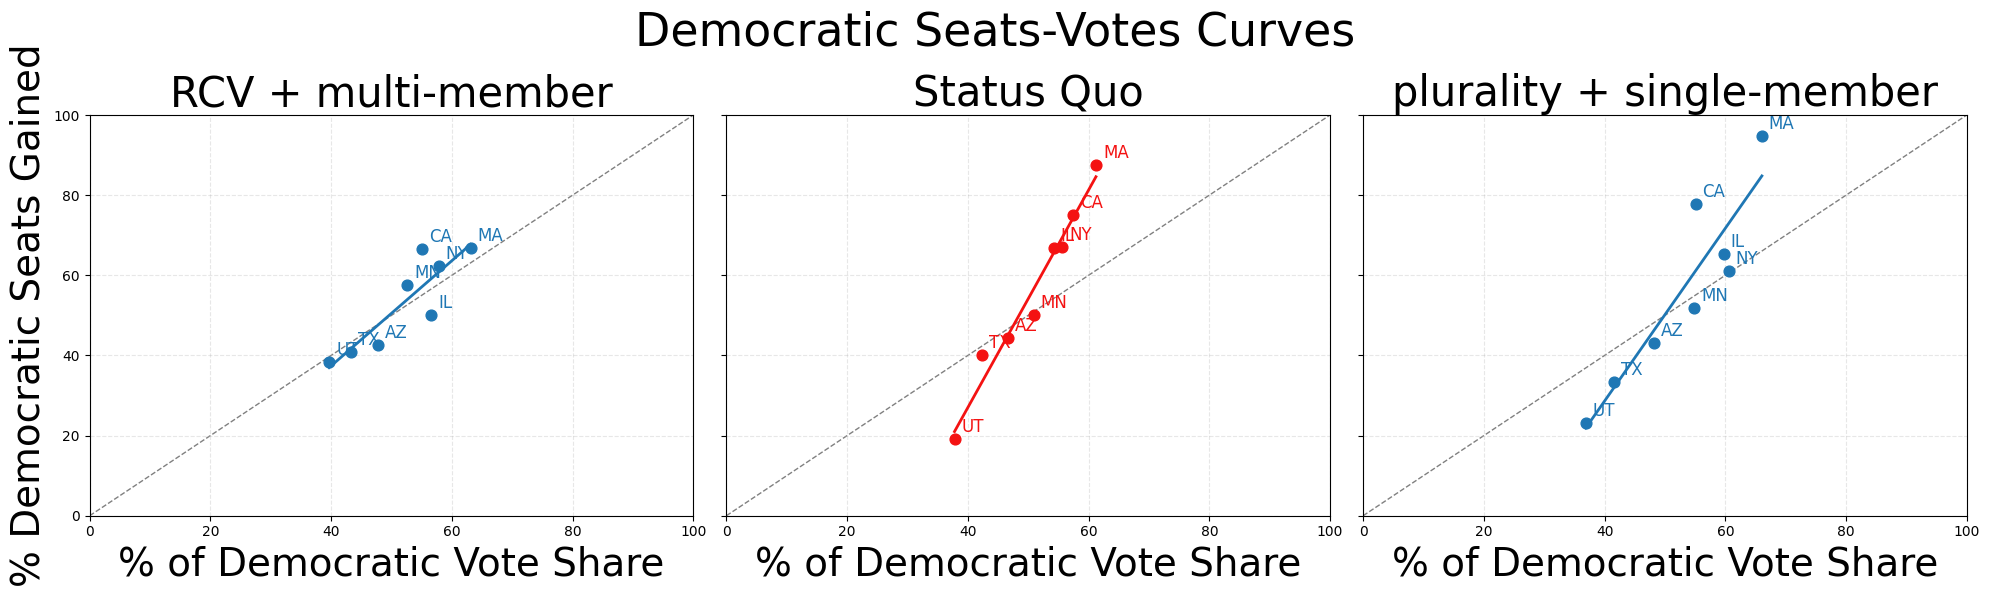

In [2]:
# Seats-Votes Plot: % of Ballots Ranking a Democratic Candidate First (x) vs. % Democratic Seats Gained (y)
# Three panels: RCV (multi-member) | Status Quo (actual current legislature) | SMD (plurality)
# Note: the RCV/SMD panels use simulated first-choice ballot share (dem_vote_share, per ensemble);
# the Status Quo panel instead uses state_props (the actual 2024 presidential vote share), since
# status_quo is itself real/current data, not a simulated ensemble quantity.
rcv_color = "#1f77b4"  # blue
smd_color = "#1f77b4"  # orange
sq_color  = "#f41212"  # green

p = "dem"

rows = []
for st in states:
    dvs_rcv = election_margins_rcv[st]["dem_vote_share"].dropna().mean() * 100
    dvs_smd = election_margins_smd[st]["dem_vote_share"].dropna().mean() * 100
    rows.append({
        "state": st,
        "dem_vote_share_rcv": dvs_rcv,
        "dem_vote_share_smd": dvs_smd,
        "dem_vote_share_actual": state_props[st]["dem"] * 100,
        "mean": np.array(seat_shares[st][p]).mean() * 100,
        "mean_smd": np.array(seat_shares_smd[st][p]).mean() * 100,
        "status_quo": status_quo[st]["dem"] * 100,
    })

fig, (ax_rcv, ax_sq, ax_smd) = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

for ax, x_key, y_key, color, marker, title in [
    (ax_rcv, "dem_vote_share_rcv", "mean", rcv_color, "o", "RCV + multi-member"),
    (ax_sq, "dem_vote_share_actual", "status_quo", sq_color, "o", "Status Quo"),
    (ax_smd, "dem_vote_share_smd", "mean_smd", smd_color, "o", "plurality + single-member"),
]:
    xs = np.array([d[x_key] for d in rows])
    ys = np.array([d[y_key] for d in rows])
    labels = [d["state"] for d in rows]

    ax.scatter(xs, ys, s=60, color=color, marker=marker, zorder=3)
    for x, y, lbl in zip(xs, ys, labels):
        ax.annotate(lbl, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=12, color=color)

    slope, intercept = np.polyfit(xs, ys, 1)
    x_fit = np.array([xs.min(), xs.max()])
    ax.plot(x_fit, slope * x_fit + intercept, color=color, linewidth=2, zorder=2)

    # Proportionality reference line (seats% = votes%)
    ax.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, zorder=0)

    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("% of Democratic Vote Share", fontsize=28)
    ax.set_title(title, fontsize=30)
    ax.grid(linestyle="--", alpha=0.3)

ax_rcv.set_ylabel("% Democratic Seats Gained", fontsize=28)
plt.suptitle("Democratic Seats-Votes Curves", fontsize=33)
plt.tight_layout()
plt.show()


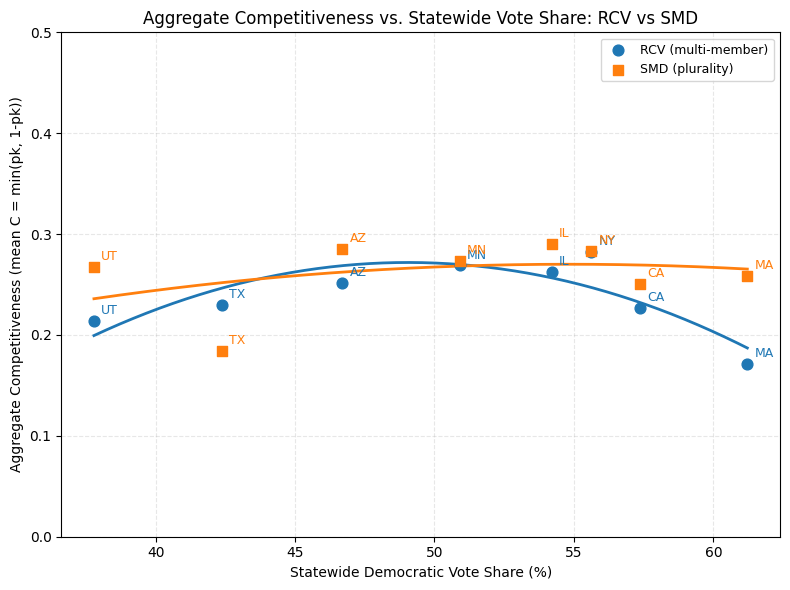

In [3]:
# Aggregate Competitiveness vs. Statewide Vote Share
# y = mean competitiveness score C = min(pk, 1-pk) across all districts/steps in a state's ensemble
# x = statewide Democratic vote share (C is symmetric between parties, so the reference party choice doesn't change C)
# One point per state; line is a quadratic fit through the state points rather than a dot-to-dot connection.
rcv_color = "#1f77b4"  # blue
smd_color = "#ff7f0e"  # orange

rows = []
for st in states:
    rows.append({
        "state": st,
        "vote_share": state_props[st]["dem"] * 100,
        "C_rcv": election_margins_rcv[st]["C"].dropna().mean(),
        "C_smd": election_margins_smd[st]["C"].dropna().mean(),
    })

xs     = np.array([d["vote_share"] for d in rows])
c_rcv  = np.array([d["C_rcv"] for d in rows])
c_smd  = np.array([d["C_smd"] for d in rows])
labels = [d["state"] for d in rows]

fig, ax = plt.subplots(figsize=(8, 6))

for ys, color, marker, label in [
    (c_rcv, rcv_color, "o", "RCV (multi-member)"),
    (c_smd, smd_color, "s", "SMD (plurality)"),
]:
    ax.scatter(xs, ys, s=60, color=color, marker=marker, zorder=3, label=label)
    for x, y, lbl in zip(xs, ys, labels):
        ax.annotate(lbl, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=9, color=color)

    coeffs = np.polyfit(xs, ys, 2)
    x_fit = np.linspace(xs.min(), xs.max(), 200)
    ax.plot(x_fit, np.polyval(coeffs, x_fit), color=color, linewidth=2, zorder=2)

ax.set_xlabel("Statewide Democratic Vote Share (%)")
ax.set_ylabel("Aggregate Competitiveness (mean C = min(pk, 1-pk))")
ax.set_ylim(0, 0.5)
ax.grid(linestyle="--", alpha=0.3)
ax.legend(loc="best", fontsize=9)
ax.set_title("Aggregate Competitiveness vs. Statewide Vote Share: RCV vs SMD")
plt.tight_layout()
plt.show()


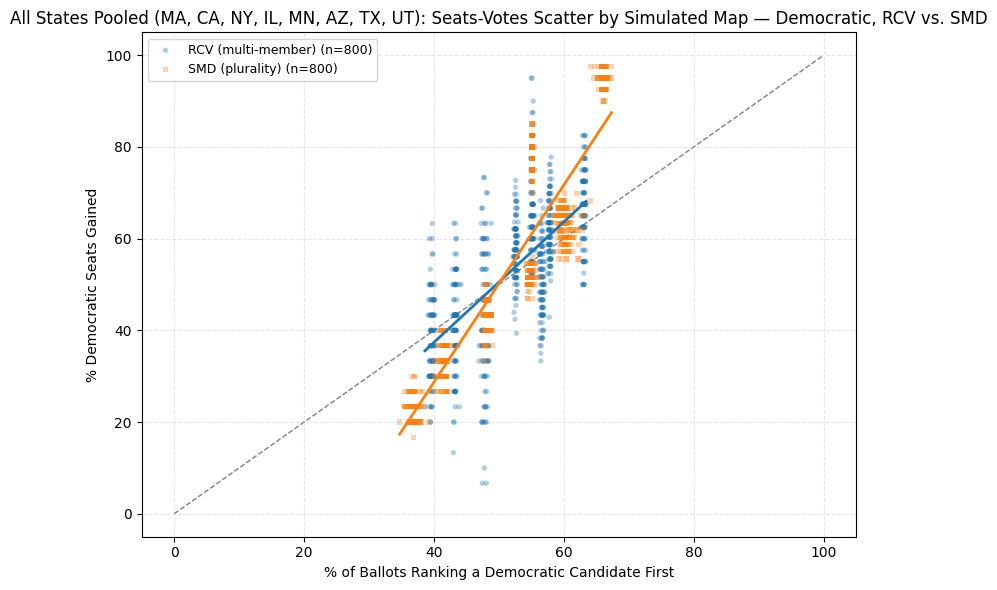

In [4]:
# Seats-Votes Scatter, All States Pooled: % of Ballots Ranking a Democratic Candidate First (x) vs. % Democratic Seats Gained (y)
# Each point = one simulated map/step (100 per state) in one state's ensemble, pooled across all states.
dem_vote_share_rcv = np.concatenate([
    election_margins_rcv[st]["dem_vote_share"].groupby(election_margins_rcv[st]["step"]).mean().values * 100
    for st in states
])
dem_seats_rcv = np.concatenate([np.array(seat_shares[st]["dem"]) * 100 for st in states])

dem_vote_share_smd = np.concatenate([
    election_margins_smd[st]["dem_vote_share"].groupby(election_margins_smd[st]["step"]).mean().values * 100
    for st in states
])
dem_seats_smd = np.concatenate([np.array(seat_shares_smd[st]["dem"]) * 100 for st in states])

fig, ax = plt.subplots(figsize=(8, 6))

for xs, ys, color, marker, label in [
    (dem_vote_share_rcv, dem_seats_rcv, rcv_color, "o", "RCV (multi-member)"),
    (dem_vote_share_smd, dem_seats_smd, smd_color, "s", "SMD (plurality)"),
]:
    ax.scatter(xs, ys, s=15, color=color, marker=marker, alpha=0.35,
               edgecolors="none", label=f"{label} (n={len(xs)})", zorder=2)
    slope, intercept = np.polyfit(xs, ys, 1)
    x_fit = np.array([xs.min(), xs.max()])
    ax.plot(x_fit, slope * x_fit + intercept, color=color, linewidth=2, zorder=3)

# Proportionality reference line (seats% = votes%)
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, zorder=1)

ax.set_xlabel("% of Ballots Ranking a Democratic Candidate First")
ax.set_ylabel("% Democratic Seats Gained")
ax.set_title(f"All States Pooled ({', '.join(states)}): Seats-Votes Scatter by Simulated Map — Democratic, RCV vs. SMD")
ax.grid(linestyle="--", alpha=0.3)
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()


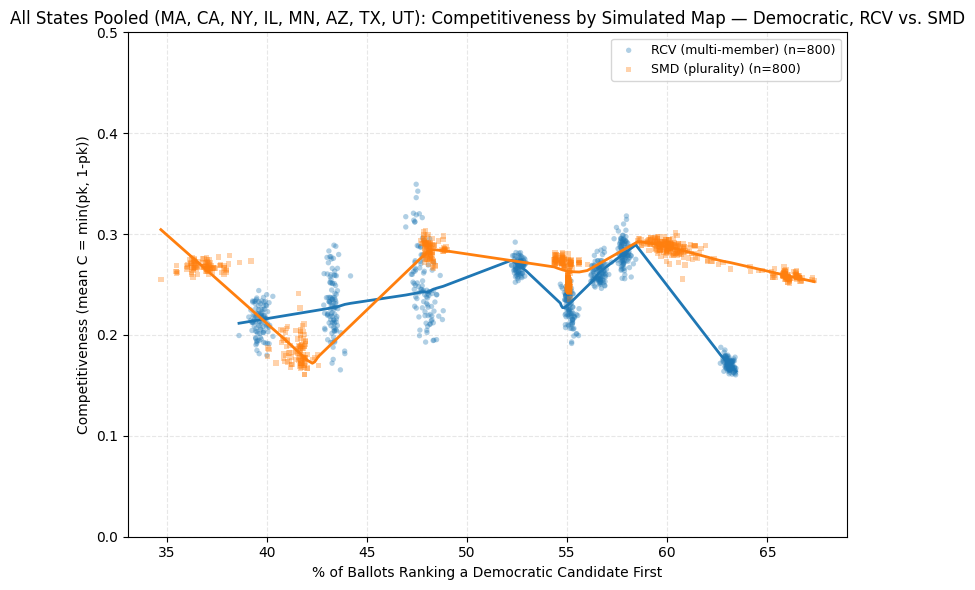

In [5]:
# Competitiveness Scatter, All States Pooled: % of Ballots Ranking a Democratic Candidate First (x) vs. Competitiveness (y)
# Each point = one simulated map/step (100 per state) in one state's ensemble, pooled across all states.
# y = mean C = min(pk, 1-pk) across districts within that step (same granularity as the x-axis).
from statsmodels.nonparametric.smoothers_lowess import lowess

dem_vote_share_rcv = np.concatenate([
    election_margins_rcv[st]["dem_vote_share"].groupby(election_margins_rcv[st]["step"]).mean().values * 100
    for st in states
])
c_rcv_pts = np.concatenate([
    election_margins_rcv[st]["C"].groupby(election_margins_rcv[st]["step"]).mean().values
    for st in states
])

dem_vote_share_smd = np.concatenate([
    election_margins_smd[st]["dem_vote_share"].groupby(election_margins_smd[st]["step"]).mean().values * 100
    for st in states
])
c_smd_pts = np.concatenate([
    election_margins_smd[st]["C"].groupby(election_margins_smd[st]["step"]).mean().values
    for st in states
])

fig, ax = plt.subplots(figsize=(8, 6))

for xs, ys, color, marker, label in [
    (dem_vote_share_rcv, c_rcv_pts, rcv_color, "o", "RCV (multi-member)"),
    (dem_vote_share_smd, c_smd_pts, smd_color, "s", "SMD (plurality)"),
]:
    ax.scatter(xs, ys, s=15, color=color, marker=marker, alpha=0.35,
               edgecolors="none", label=f"{label} (n={len(xs)})", zorder=2)
    smoothed = lowess(ys, xs, frac=0.3, return_sorted=True)
    ax.plot(smoothed[:, 0], smoothed[:, 1], color=color, linewidth=2, zorder=3)

ax.set_xlabel("% of Ballots Ranking a Democratic Candidate First")
ax.set_ylabel("Competitiveness (mean C = min(pk, 1-pk))")
ax.set_ylim(0, 0.5)
ax.set_title(f"All States Pooled ({', '.join(states)}): Competitiveness by Simulated Map — Democratic, RCV vs. SMD")
ax.grid(linestyle="--", alpha=0.3)
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()


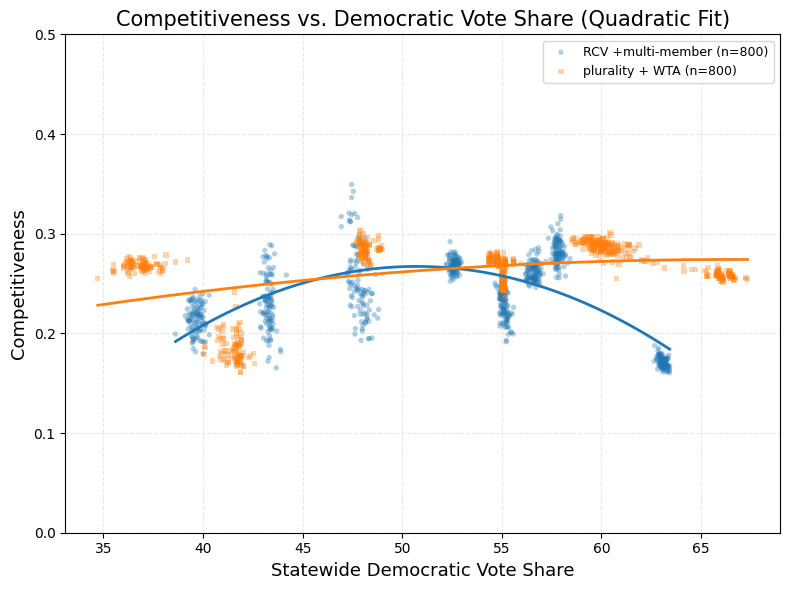

In [6]:
# Competitiveness Scatter, All States Pooled (Quadratic Fit): % of Ballots Ranking a Democratic Candidate First (x) vs. Competitiveness (y)
# Each point = one simulated map/step (100 per state) in one state's ensemble, pooled across all states.
# y = mean C = min(pk, 1-pk) across districts within that step (same granularity as the x-axis).
dem_vote_share_rcv = np.concatenate([
    election_margins_rcv[st]["dem_vote_share"].groupby(election_margins_rcv[st]["step"]).mean().values * 100
    for st in states
])
c_rcv_pts = np.concatenate([
    election_margins_rcv[st]["C"].groupby(election_margins_rcv[st]["step"]).mean().values
    for st in states
])

dem_vote_share_smd = np.concatenate([
    election_margins_smd[st]["dem_vote_share"].groupby(election_margins_smd[st]["step"]).mean().values * 100
    for st in states
])
c_smd_pts = np.concatenate([
    election_margins_smd[st]["C"].groupby(election_margins_smd[st]["step"]).mean().values
    for st in states
])

fig, ax = plt.subplots(figsize=(8, 6))

for xs, ys, color, marker, label in [
    (dem_vote_share_rcv, c_rcv_pts, rcv_color, "o", "RCV +multi-member"),
    (dem_vote_share_smd, c_smd_pts, smd_color, "s", "plurality + WTA"),
]:
    ax.scatter(xs, ys, s=15, color=color, marker=marker, alpha=0.35,
               edgecolors="none", label=f"{label} (n={len(xs)})", zorder=2)
    coeffs = np.polyfit(xs, ys, 2)
    x_fit = np.linspace(xs.min(), xs.max(), 200)
    ax.plot(x_fit, np.polyval(coeffs, x_fit), color=color, linewidth=2, zorder=3)

ax.set_xlabel("Statewide Democratic Vote Share", fontsize=13)
ax.set_ylabel("Competitiveness", fontsize=13)
ax.set_ylim(0, 0.5)
ax.set_title(f"Competitiveness vs. Democratic Vote Share (Quadratic Fit)", fontsize=15)
ax.grid(linestyle="--", alpha=0.3)
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()


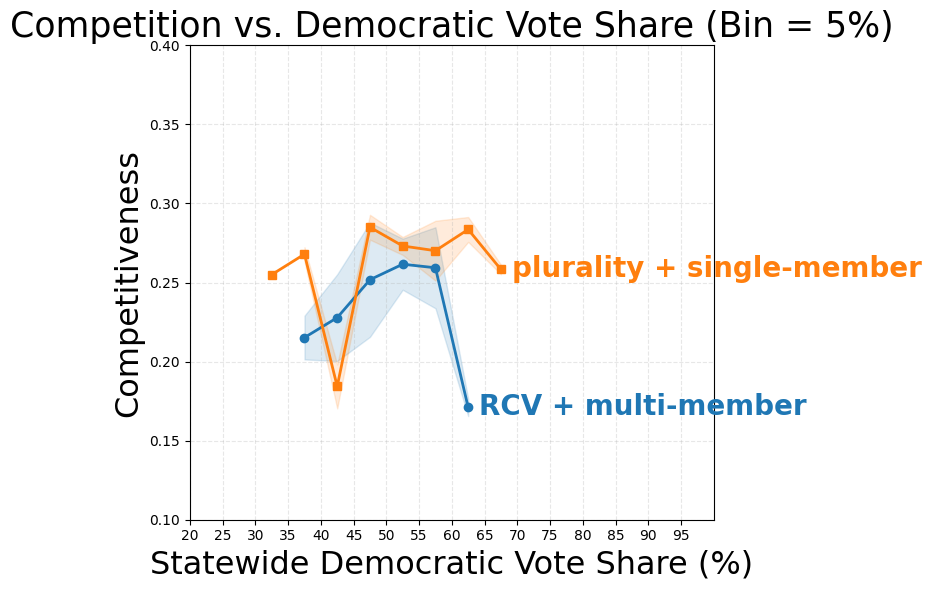

In [7]:
# Competitiveness by Democratic Vote-Share Bin, All States Pooled
# Same pooled per-step data as the scatter/LOWESS/quadratic cells above, but instead of fitting a
# smooth curve, bin Democratic first-choice vote share into 5-point-wide bins (0-5%, 5-10%, ...,
# 95-100%) and plot the mean Competitiveness (C) within each bin.
# Shaded band = +/- 1 std of the raw pooled points within each bin (reflects the underlying noise/
# spread of C, not the precision of the mean -- unlike a standard-error band, this doesn't shrink
# just because a bin happens to contain a lot of points).
dem_vote_share_rcv = np.concatenate([
    election_margins_rcv[st]["dem_vote_share"].groupby(election_margins_rcv[st]["step"]).mean().values * 100
    for st in states
])
c_rcv_pts = np.concatenate([
    election_margins_rcv[st]["C"].groupby(election_margins_rcv[st]["step"]).mean().values
    for st in states
])

dem_vote_share_smd = np.concatenate([
    election_margins_smd[st]["dem_vote_share"].groupby(election_margins_smd[st]["step"]).mean().values * 100
    for st in states
])
c_smd_pts = np.concatenate([
    election_margins_smd[st]["C"].groupby(election_margins_smd[st]["step"]).mean().values
    for st in states
])

bin_edges = np.arange(0, 101, 5)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

fig, ax = plt.subplots(figsize=(8, 6))

for xs, ys, color, marker, label in [
    (dem_vote_share_rcv, c_rcv_pts, rcv_color, "o", "RCV + multi-member"),
    (dem_vote_share_smd, c_smd_pts, smd_color, "s", "plurality + single-member"),
]:
    bin_idx = np.clip(np.digitize(xs, bin_edges) - 1, 0, len(bin_centers) - 1)
    bin_means = np.array([ys[bin_idx == i].mean() if np.any(bin_idx == i) else np.nan for i in range(len(bin_centers))])
    bin_stds  = np.array([ys[bin_idx == i].std(ddof=1) if np.sum(bin_idx == i) > 1 else np.nan for i in range(len(bin_centers))])
    valid = ~np.isnan(bin_means)

    ax.fill_between(bin_centers[valid], (bin_means - bin_stds)[valid], (bin_means + bin_stds)[valid],
                     color=color, alpha=0.15, zorder=1)
    ax.plot(bin_centers[valid], bin_means[valid], color=color, marker=marker, linewidth=2, zorder=2)

    # Direct label beside the line's rightmost point instead of a legend
    last_x, last_y = bin_centers[valid][-1], bin_means[valid][-1]
    ax.annotate(label, (last_x, last_y), textcoords="offset points", xytext=(8, 0),
                fontsize=20, color=color, va="center", fontweight="bold")
ax.set_xlabel("Statewide Democratic Vote Share (%)", fontsize=23)
ax.set_ylabel("Competitiveness", fontsize=23)
ax.set_ylim(0.1, 0.4)
ax.set_xlim(20, 100)
ax.set_xticks(np.arange(20, 100, 5))
ax.set_title(f"Competition vs. Democratic Vote Share (Bin = 5%)", fontsize=25)
ax.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


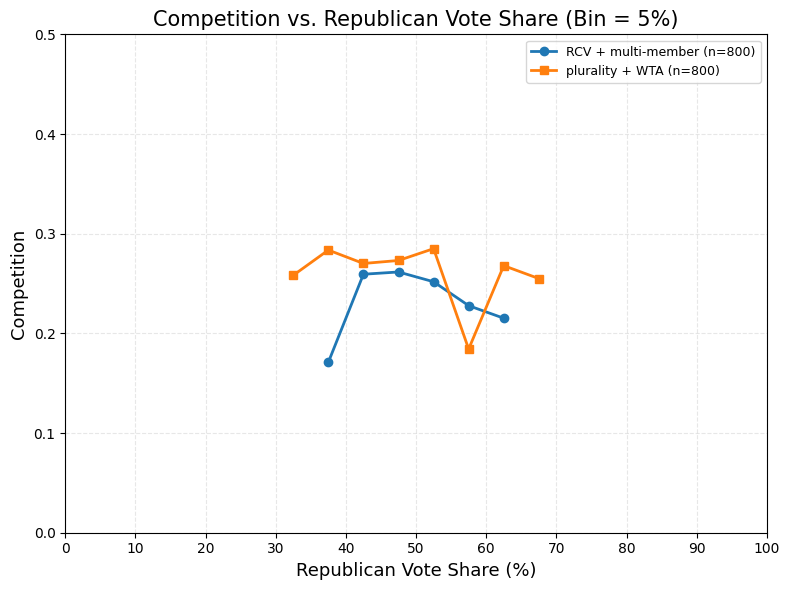

In [8]:
# Competitiveness by Republican Vote-Share Bin, All States Pooled
# Same as the Democratic binned plot above (5-point-wide bins), but x = Republican first-choice vote share.
# There's no separate rep_vote_share column -- since every ballot ranks either a dem or rep
# candidate first, Republican share = 1 - dem_vote_share, so this is the mirror image of the
# Democratic plot (C itself is symmetric, C = min(pk, 1-pk), so the y-values only reshuffle bins).
rep_vote_share_rcv = 100 - dem_vote_share_rcv
rep_vote_share_smd = 100 - dem_vote_share_smd

fig, ax = plt.subplots(figsize=(8, 6))

for xs, ys, color, marker, label in [
    (rep_vote_share_rcv, c_rcv_pts, rcv_color, "o", "RCV + multi-member"),
    (rep_vote_share_smd, c_smd_pts, smd_color, "s", "plurality + WTA"),
]:
    bin_idx = np.clip(np.digitize(xs, bin_edges) - 1, 0, len(bin_centers) - 1)
    bin_means  = np.array([ys[bin_idx == i].mean() if np.any(bin_idx == i) else np.nan for i in range(len(bin_centers))])
    valid = ~np.isnan(bin_means)

    ax.plot(bin_centers[valid], bin_means[valid], color=color, marker=marker, linewidth=2, zorder=2,
            label=f"{label} (n={len(xs)})")

ax.set_xlabel("Republican Vote Share (%)", fontsize=13)
ax.set_ylabel("Competition", fontsize=13)
ax.set_ylim(0, 0.5)
ax.set_xlim(0, 100)
ax.set_xticks(np.arange(0, 101, 10))
ax.set_title(f"Competition vs. Republican Vote Share (Bin = 5%)", fontsize=15)
ax.grid(linestyle="--", alpha=0.3)
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()


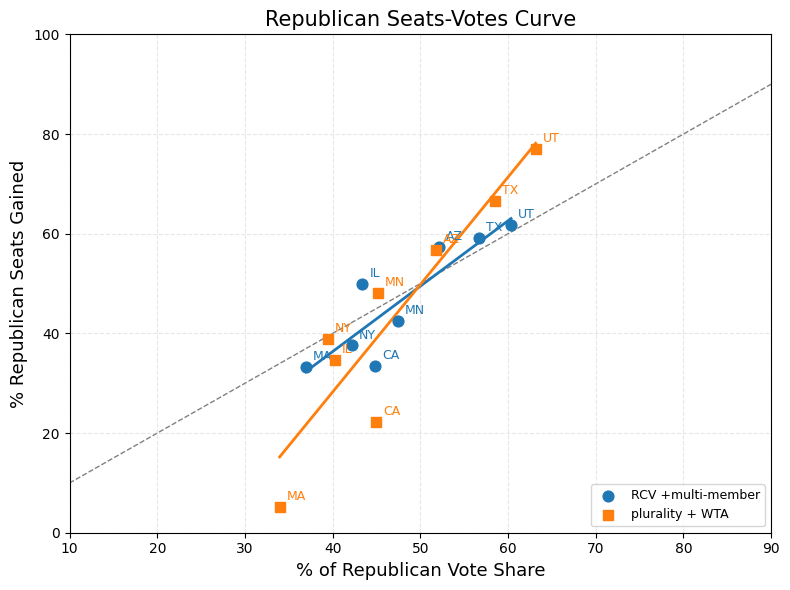

In [9]:
# Seats-Votes Plot: % of Ballots Ranking a Republican Candidate First (x) vs. % Republican Seats Gained (y)
# Compares the multi-member RCV ensemble against the single-member-district (SMD/plurality) ensemble
# One point per state; line is a linear trend fit through the state points rather than a dot-to-dot connection.
# There's no separate rep_vote_share column -- Republican share = 1 - dem_vote_share.
p = "rep"

fig, ax = plt.subplots(figsize=(8, 6))

rows = []
for st in states:
    rvs_rcv = 100 - election_margins_rcv[st]["dem_vote_share"].dropna().mean() * 100
    rvs_smd = 100 - election_margins_smd[st]["dem_vote_share"].dropna().mean() * 100
    rows.append({
        "state": st,
        "rep_vote_share_rcv": rvs_rcv,
        "rep_vote_share_smd": rvs_smd,
        "mean": np.array(seat_shares[st][p]).mean() * 100,
        "mean_smd": np.array(seat_shares_smd[st][p]).mean() * 100,
    })

for x_key, y_key, color, marker, label in [
    ("rep_vote_share_rcv", "mean", rcv_color, "o", "RCV +multi-member"),
    ("rep_vote_share_smd", "mean_smd", smd_color, "s", "plurality + WTA"),
]:
    xs = np.array([d[x_key] for d in rows])
    ys = np.array([d[y_key] for d in rows])
    labels = [d["state"] for d in rows]

    ax.scatter(xs, ys, s=60, color=color, marker=marker, zorder=3, label=label)
    for x, y, lbl in zip(xs, ys, labels):
        ax.annotate(lbl, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=9, color=color)

    slope, intercept = np.polyfit(xs, ys, 1)
    x_fit = np.array([xs.min(), xs.max()])
    ax.plot(x_fit, slope * x_fit + intercept, color=color, linewidth=2, zorder=2)

# Proportionality reference line (seats% = votes%)
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, zorder=0)

ax.set_xlim(10, 90)
ax.set_ylim(0, 100)
ax.set_xlabel("% of Republican Vote Share", fontsize=13)
ax.set_ylabel("% Republican Seats Gained", fontsize=13)
ax.set_title("Republican Seats-Votes Curve", fontsize=15)
ax.grid(linestyle="--", alpha=0.3)
ax.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()


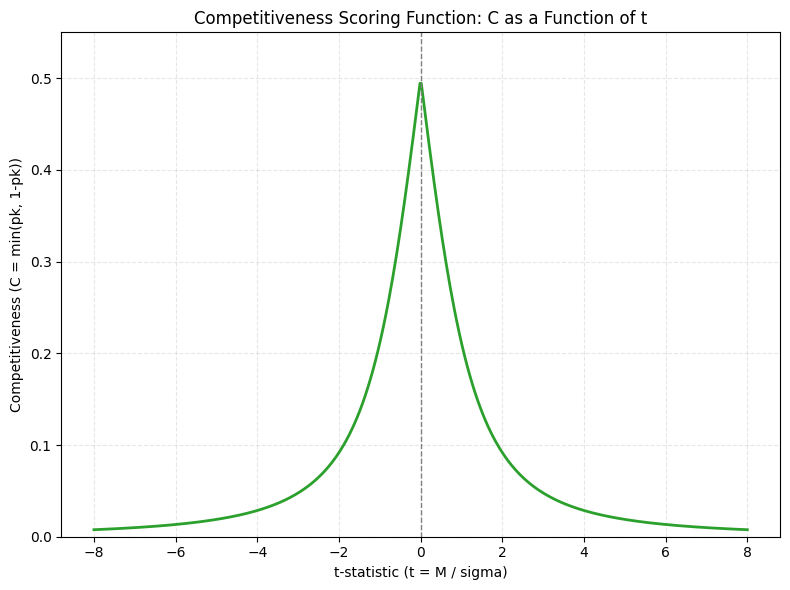

In [10]:
# Competitiveness Scoring Function: x = t-statistic (t = M / sigma) vs. y = Competitiveness (C)
# This is the deterministic transformation used to compute C from the underlying vote-share data
# in each state's *_Partisan.ipynb (election_sim): M = dem_vote_share - 0.5 (distance from a 50/50
# toss-up), t = M / sigma (standardized by that district's std dev of vote share across the
# ensemble), pk = t_dist.cdf(t, df=2), C = min(pk, 1-pk). Unlike the other plots in this notebook,
# this curve doesn't depend on any state's data -- it's the scoring function itself.
from scipy.stats import t as t_dist

t_vals = np.linspace(-8, 8, 500)
pk_vals = t_dist.cdf(t_vals, df=2)
c_vals = np.minimum(pk_vals, 1 - pk_vals)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(t_vals, c_vals, color="#2ca02c", linewidth=2)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)

ax.set_xlabel("t-statistic (t = M / sigma)")
ax.set_ylabel("Competitiveness (C = min(pk, 1-pk))")
ax.set_ylim(0, 0.55)
ax.set_title("Competitiveness Scoring Function: C as a Function of t")
ax.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


SMD ensemble mean sigma (pooled across 8 states): 0.1470


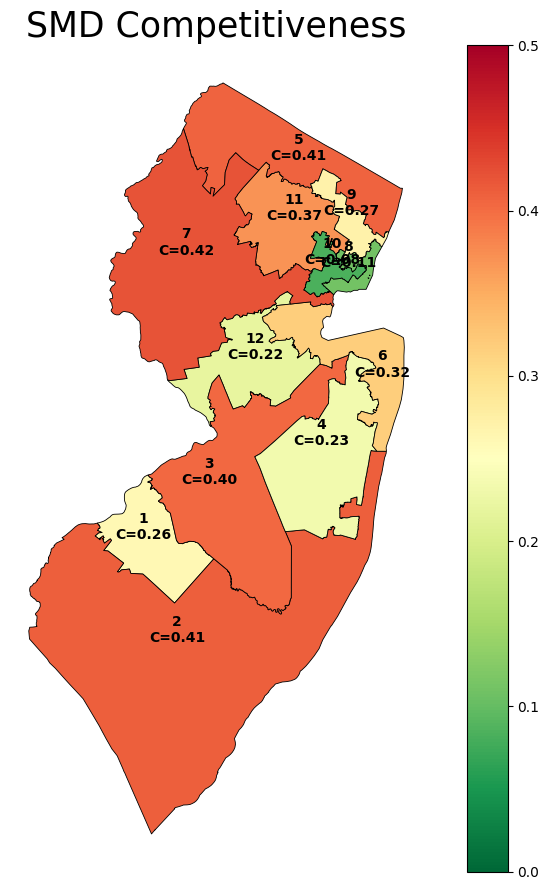

In [11]:
# NJ Map 1: Actual 12 SMDs, Colored by CURRENT (DRA Composite) Competitiveness
#
# NOT simulated -- these are NJ's real, currently-used single-member districts (118th Congress
# boundaries, Census TIGER tl_2023_34_cd118). Dem share here is Dave's Redistricting App's
# Composite partisan index per district (2022 vintage -- same map used through 2024, no NJ
# redistricting since), user-provided from a manual DRA export (NJ-2022-Congressional-district-
# statistics.csv).
#
# C = min(p, 1-p), p = t_dist.cdf(t, df=2), t = M/sigma, M = dem_frac - 0.5 -- same formula as
# Map 2 and everywhere else in this notebook. sigma here is the REAL, computed mean of each
# district's own "sigma" column (std dev of vote share across the 100-map ensemble) pooled across
# all 359 districts in the 8-state SMD ensemble -- not an invented/hand-picked number. This differs
# from Map 2's bin-lookup approach: bin-lookup blends together many real districts that individually
# have very different sigmas (0.037 in CA up to 0.33 in NY), which smooths out the sharp differences
# near a 50/50 vote share; applying ONE consistent averaged sigma directly via the formula preserves
# that sharpness instead, so e.g. NJ-7 (closest to 50/50) comes out clearly higher than the rest.
import geopandas as gpd
from scipy.stats import t as t_dist

nj_dem_share = {
    1: 61.28, 2: 46.23, 3: 54.07, 4: 36.86, 5: 53.89, 6: 58.14,
    7: 46.71, 8: 75.82, 9: 60.79, 10: 81.61, 11: 55.61, 12: 64.05,
}

SIGMA = np.mean([
    election_margins_smd[st].groupby("district")["sigma"].first().mean()
    for st in states
])
print(f"SMD ensemble mean sigma (pooled across {len(states)} states): {SIGMA:.4f}")

def compute_C(dem_pct, sigma=SIGMA):
    M = dem_pct / 100 - 0.5
    t = M / sigma
    p = t_dist.cdf(t, df=2)
    return min(p, 1 - p)

nj_gdf = gpd.read_file("/Users/zhaoyiran/Desktop/Data/NJ/tl_2023_34_cd118/tl_2023_34_cd118.shp")
nj_gdf["district"] = nj_gdf["CD118FP"].astype(int)
nj_gdf["dem_share"] = nj_gdf["district"].map(nj_dem_share)
nj_gdf["C"] = nj_gdf["dem_share"].apply(compute_C)

fig, ax = plt.subplots(figsize=(9, 9))
nj_gdf.plot(column="C", cmap="RdYlGn_r", vmin=0, vmax=0.5, edgecolor="black", linewidth=0.6,
            legend=True, ax=ax)

for _, row in nj_gdf.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{row['district']}\nC={row['C']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=10, fontweight="bold")

ax.set_axis_off()
plt.title("SMD Competitiveness", fontsize=25)
plt.tight_layout()
plt.show()


 superdistrict  avg_dem_share  per_district_C  out_of_range
             1      53.860000        0.261586         False
             2      53.016667        0.261586         False
             3      52.070000        0.261586         False
             4      72.740000        0.171013          True

Status quo (12 SMDs, pooled SMD-ensemble sigma): mean C = 0.292, sum = 3.509
Superdistricts (RCV bin-lookup, per-district C): mean = 0.239, sum = 0.956


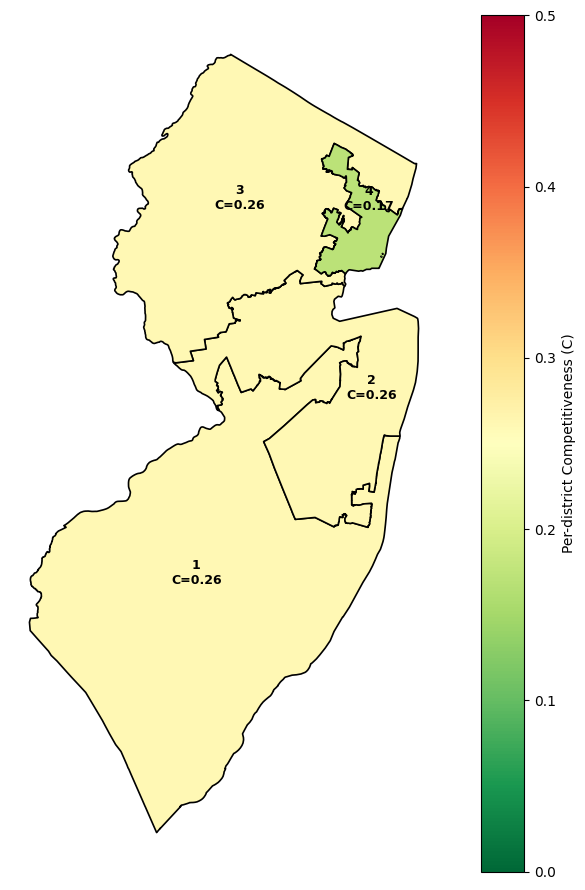

In [12]:
# NJ Map 2: 4 Superdistricts (3-Winner MMD), Colored by RCV Ensemble Bin-Lookup Competitiveness
#
# NJ's 12 current districts dissolved into 4 geographic superdistricts of 3 original districts each,
# each electing 3 members via RCV. The grouping is MY OWN regional approximation (South /
# Central-Shore / Northwest / Northeast-Urban) -- not an official DRA proposal; treat it as
# illustrative, not a precise map.
#
# LABEL FIX: this value is PER-DISTRICT competitiveness, not "single-seat." The RCV bin curve
# (c_rcv_pts, built in cell 25f8e12f) is sourced from election_margins_rcv[st]["C"] -- and in the real
# 8-state ensemble, "district" already means the whole multi-member at-large contest (all seats in
# that district are decided from one shared ballot count; there's no such thing as a per-individual-
# seat vote share in real multi-winner RCV). So looking a superdistrict's average vote share up in
# this curve returns a real per-district-scale C, directly comparable to the SMD maps' per-district C
# -- not a "single seat" value that then needs combining across 3 seats.
nj_superdistricts = {
    1: [1, 2, 3],      # South Jersey
    2: [4, 6, 12],     # Central / Shore
    3: [5, 7, 11],     # Northwest (contains NJ-7)
    4: [8, 9, 10],     # Northeast Urban
}
district_to_sd = {d: sd for sd, ds in nj_superdistricts.items() for d in ds}
nj_gdf["superdistrict"] = nj_gdf["district"].map(district_to_sd)

def bin_means_of(xs, ys, bin_edges, bin_centers):
    bin_idx = np.clip(np.digitize(xs, bin_edges) - 1, 0, len(bin_centers) - 1)
    return np.array([ys[bin_idx == i].mean() if np.any(bin_idx == i) else np.nan for i in range(len(bin_centers))])

def lookup_bin(vote_share, bin_edges, bin_centers, bin_vals):
    idx = np.clip(np.digitize(vote_share, bin_edges) - 1, 0, len(bin_centers) - 1)
    out_of_range = np.isnan(bin_vals[idx])
    if out_of_range:
        valid_idx = np.where(~np.isnan(bin_vals))[0]
        idx = valid_idx[np.argmin(np.abs(valid_idx - idx))]
    return bin_vals[idx], out_of_range

rcv_bin_means = bin_means_of(dem_vote_share_rcv, c_rcv_pts, bin_edges, bin_centers)

sd_rows = []
for name, districts in nj_superdistricts.items():
    avg_share = np.mean([nj_dem_share[d] for d in districts])
    c_val, oor = lookup_bin(avg_share, bin_edges, bin_centers, rcv_bin_means)
    sd_rows.append({"superdistrict": name, "avg_dem_share": avg_share, "per_district_C": c_val, "out_of_range": oor})
sd_df = pd.DataFrame(sd_rows)
print(sd_df.to_string(index=False))
print(f"\nStatus quo (12 SMDs, pooled SMD-ensemble sigma): mean C = {nj_gdf['C'].mean():.3f}, sum = {nj_gdf['C'].sum():.3f}")
print(f"Superdistricts (RCV bin-lookup, per-district C): mean = {sd_df['per_district_C'].mean():.3f}, sum = {sd_df['per_district_C'].sum():.3f}")

sd_gdf = nj_gdf.dissolve(by="superdistrict").reset_index().merge(sd_df, on="superdistrict")

fig, ax = plt.subplots(figsize=(9, 9))
sd_gdf.plot(column="per_district_C", cmap="RdYlGn_r", vmin=0, vmax=0.5, edgecolor="black", linewidth=1.2,
            legend=True, legend_kwds={"label": "Per-district Competitiveness (C)"}, ax=ax)

for _, row in sd_gdf.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{row['superdistrict']}\nC={row['per_district_C']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=9, fontweight="bold")

ax.set_axis_off()
plt.tight_layout()
plt.show()


 district  dem_share        C  C_binlookup  out_of_range
        1      61.28 0.261594     0.283570         False
        2      46.23 0.410806     0.284978         False
        3      54.07 0.403961     0.273113         False
        4      36.86 0.232909     0.267936         False
        5      53.89 0.408061     0.273113         False
        6      58.14 0.317743     0.270121         False
        7      46.71 0.421865     0.284978         False
        8      75.82 0.110588     0.258265          True
        9      60.79 0.269714     0.283570         False
       10      81.61 0.082283     0.258265          True
       11      55.61 0.369766     0.270121         False
       12      64.05 0.220078     0.283570         False

Map 1 (direct formula, pooled sigma): mean C = 0.292, sum = 3.509
Map 3 (SMD bin-lookup):               mean C = 0.274, sum = 3.292


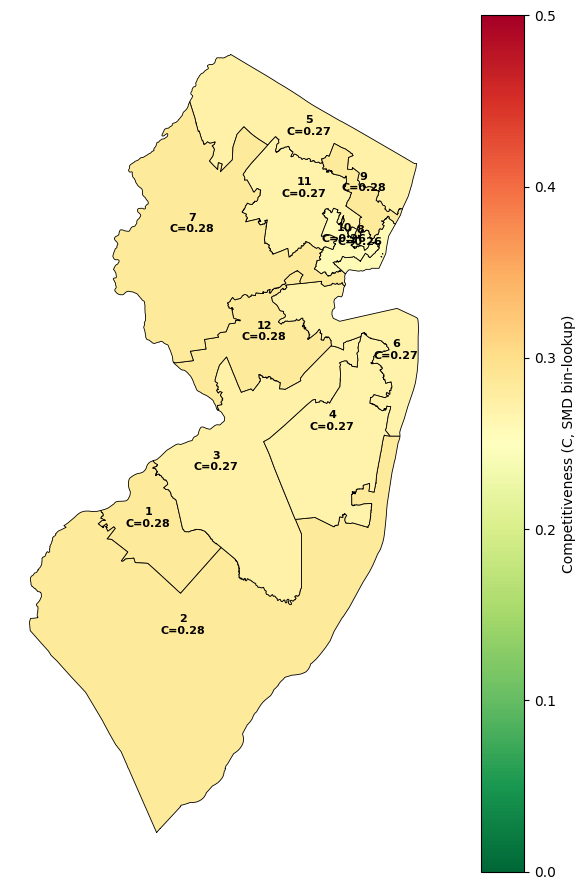

In [13]:
# NJ Map 3: Actual 12 SMDs (same as Map 1), Colored by SMD Ensemble Bin-Lookup Competitiveness
#
# Identical setup to Map 1 (same real districts, same DRA vote shares) but using the SMD ensemble's
# bin-lookup instead of the pooled-sigma direct formula -- the SMD analog of what Map 2 currently
# does with the RCV ensemble. Each district's Dem share is dropped into the SMD bin curve built in
# cell 25f8e12f (mean C of real simulated districts/steps landing near that vote share), rather than
# applying one consistent sigma via the formula. Expect this to look flatter/less differentiated than
# Map 1 -- that's the same effect noted for Map 2's bin-lookup version, just applied here to SMD.
smd_bin_means = bin_means_of(dem_vote_share_smd, c_smd_pts, bin_edges, bin_centers)

nj_gdf["C_binlookup"] = nj_gdf["dem_share"].apply(lambda s: lookup_bin(s, bin_edges, bin_centers, smd_bin_means)[0])
nj_gdf["out_of_range"] = nj_gdf["dem_share"].apply(lambda s: lookup_bin(s, bin_edges, bin_centers, smd_bin_means)[1])

print(nj_gdf[["district", "dem_share", "C", "C_binlookup", "out_of_range"]].sort_values("district").to_string(index=False))
print(f"\nMap 1 (direct formula, pooled sigma): mean C = {nj_gdf['C'].mean():.3f}, sum = {nj_gdf['C'].sum():.3f}")
print(f"Map 3 (SMD bin-lookup):               mean C = {nj_gdf['C_binlookup'].mean():.3f}, sum = {nj_gdf['C_binlookup'].sum():.3f}")

fig, ax = plt.subplots(figsize=(9, 9))
nj_gdf.plot(column="C_binlookup", cmap="RdYlGn_r", vmin=0, vmax=0.5, edgecolor="black", linewidth=0.6,
            legend=True, legend_kwds={"label": "Competitiveness (C, SMD bin-lookup)"}, ax=ax)

for _, row in nj_gdf.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{row['district']}\nC={row['C_binlookup']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=8, fontweight="bold")

ax.set_axis_off()
plt.tight_layout()
plt.show()


RCV ensemble mean sigma (pooled across 8 states): 0.1004  (vs. SMD sigma: 0.1470)
 superdistrict  avg_dem_share  per_district_C
             1      53.860000        0.368803
             2      53.016667        0.396065
             3      52.070000        0.427852
             4      72.740000        0.075857

Map 2 (RCV bin-lookup, per-district C):   mean = 0.239, sum = 0.956
Map 4 (RCV direct, pooled sigma, per-district C): mean = 0.317, sum = 1.269


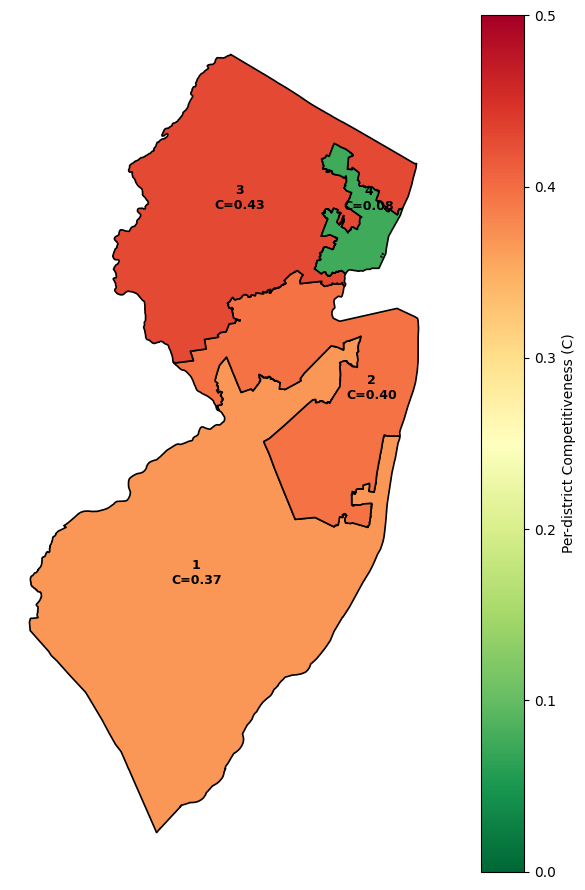

In [14]:
# NJ Map 4: 4 Superdistricts (same as Map 2), Colored by Directly-Computed Per-District Competitiveness (RCV sigma)
#
# Identical setup to Map 2 (same superdistrict grouping, same averaged DRA vote shares) but computes
# C directly via the formula -- C = min(p, 1-p), p = t_dist.cdf(t, df=2), t = M/sigma -- using ONE
# pooled sigma from the RCV ensemble, instead of the bin-lookup. This is the RCV analog of what
# Map 1 already does with the SMD ensemble's pooled sigma.
#
# LABEL FIX: SIGMA_RCV comes from election_margins_rcv[st].groupby("district")["sigma"] -- and in the
# real 8-state ensemble, "district" already IS the whole multi-member at-large contest (all seats in
# a district share one ballot count; there's no per-individual-seat vote share in real multi-winner
# RCV). So compute_C(avg_share, sigma=SIGMA_RCV) is already a PER-DISTRICT competitiveness value on
# the same scale as SMD's per-district C -- not a "single seat" value needing further combination
# across 3 seats.
#
# Note: RCV sigma (0.102) is SMALLER than SMD sigma (0.160), not larger -- RCV's multi-member
# districts are fewer/larger, so they aggregate more precincts and their vote share swings LESS
# across the redistricting ensemble than single-member districts do.
SIGMA_RCV = np.mean([
    election_margins_rcv[st].groupby("district")["sigma"].first().mean()
    for st in states
])
print(f"RCV ensemble mean sigma (pooled across {len(states)} states): {SIGMA_RCV:.4f}  (vs. SMD sigma: {SIGMA:.4f})")

sd_rows_direct = []
for name, districts in nj_superdistricts.items():
    avg_share = np.mean([nj_dem_share[d] for d in districts])
    c_val = compute_C(avg_share, sigma=SIGMA_RCV)
    sd_rows_direct.append({"superdistrict": name, "avg_dem_share": avg_share, "per_district_C": c_val})
sd_df_direct = pd.DataFrame(sd_rows_direct)
print(sd_df_direct.to_string(index=False))
print(f"\nMap 2 (RCV bin-lookup, per-district C):   mean = {sd_df['per_district_C'].mean():.3f}, sum = {sd_df['per_district_C'].sum():.3f}")
print(f"Map 4 (RCV direct, pooled sigma, per-district C): mean = {sd_df_direct['per_district_C'].mean():.3f}, sum = {sd_df_direct['per_district_C'].sum():.3f}")

sd_gdf_direct = nj_gdf.dissolve(by="superdistrict").reset_index().merge(sd_df_direct, on="superdistrict")

fig, ax = plt.subplots(figsize=(9, 9))
sd_gdf_direct.plot(column="per_district_C", cmap="RdYlGn_r", vmin=0, vmax=0.5, edgecolor="black", linewidth=1.2,
                    legend=True, legend_kwds={"label": "Per-district Competitiveness (C)"}, ax=ax)

for _, row in sd_gdf_direct.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{row['superdistrict']}\nC={row['per_district_C']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=9, fontweight="bold")

ax.set_axis_off()
plt.tight_layout()
plt.show()


superdistrict  districts  avg_dem_share  per_district_C
            X  [1, 2, 4]      48.123333        0.434468
            Y [3, 6, 12]      58.753333        0.237565
            Z [5, 9, 11]      56.763333        0.284938
            W [7, 8, 10]      68.046667        0.107008

Map 4 (original grouping, per-district C):    mean = 0.317, sum = 1.269
Map 5 (alternative grouping, per-district C): mean = 0.266, sum = 1.064


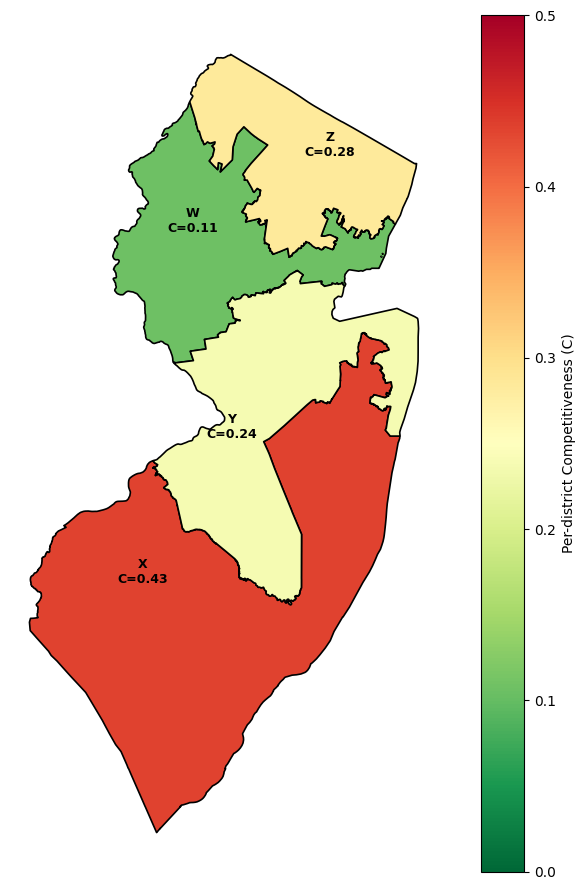

In [15]:
# NJ Map 5: 4 Superdistricts, ALTERNATIVE Grouping (Same Direct-Formula Method as Map 4)
#
# Same method as Map 4 (direct formula, pooled RCV sigma -- a real PER-DISTRICT competitiveness,
# directly comparable to SMD's per-district C, see the label fix noted in Map 4) -- only the
# superdistrict GROUPING changes, to show how much that single design choice moves the result.
# Verified geographically contiguous using the actual shapefile's adjacency graph (districts sharing
# a border), same as Maps 2/4's grouping was -- this isn't an arbitrary redraw, it's a different but
# equally valid partition of the same 12 districts into 4 contiguous 3-district groups.
#
# Key difference from before: NJ-7 (the closest-to-50/50 district) is now grouped with two safely-
# Democratic districts (8, 10) instead of two other lean/competitive ones (5, 11) -- so its own
# closeness gets diluted into a much less competitive composite, rather than reinforced.
nj_superdistricts_v2 = {
    "X": [1, 2, 4],
    "Y": [3, 6, 12],
    "Z": [5, 9, 11],
    "W": [7, 8, 10],   # NJ-7 now paired with two Newark/Jersey City landslide-Dem seats
}
district_to_sd_v2 = {d: sd for sd, ds in nj_superdistricts_v2.items() for d in ds}
nj_gdf["superdistrict_v2"] = nj_gdf["district"].map(district_to_sd_v2)

sd_rows_v2 = []
for name, districts in nj_superdistricts_v2.items():
    avg_share = np.mean([nj_dem_share[d] for d in districts])
    c_val = compute_C(avg_share, sigma=SIGMA_RCV)
    sd_rows_v2.append({"superdistrict": name, "districts": districts, "avg_dem_share": avg_share, "per_district_C": c_val})
sd_df_v2 = pd.DataFrame(sd_rows_v2)
print(sd_df_v2.to_string(index=False))
print(f"\nMap 4 (original grouping, per-district C):    mean = {sd_df_direct['per_district_C'].mean():.3f}, sum = {sd_df_direct['per_district_C'].sum():.3f}")
print(f"Map 5 (alternative grouping, per-district C): mean = {sd_df_v2['per_district_C'].mean():.3f}, sum = {sd_df_v2['per_district_C'].sum():.3f}")

sd_gdf_v2 = nj_gdf.dissolve(by="superdistrict_v2").reset_index().merge(
    sd_df_v2.rename(columns={"superdistrict": "superdistrict_v2"}), on="superdistrict_v2"
)

fig, ax = plt.subplots(figsize=(9, 9))
sd_gdf_v2.plot(column="per_district_C", cmap="RdYlGn_r", vmin=0, vmax=0.5, edgecolor="black", linewidth=1.2,
               legend=True, legend_kwds={"label": "Per-district Competitiveness (C)"}, ax=ax)

for _, row in sd_gdf_v2.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{row['superdistrict_v2']}\nC={row['per_district_C']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=9, fontweight="bold")

ax.set_axis_off()
plt.tight_layout()
plt.show()


35 geometrically valid contiguous 4x3 groupings found.
Std dev of the 4 per-district C values ranges from 0.0945 (most even) to 0.1544 (least even) across all of them.

Most even grouping selected:
  groups = [(1, 3, 12), (2, 4, 6), (5, 8, 9), (7, 10, 11)]
  C = [np.float64(0.216), np.float64(0.399), np.float64(0.155), np.float64(0.188)], mean = 0.240, std = 0.0945

superdistrict   districts  avg_dem_share  per_district_C
            A  [1, 3, 12]      59.800000        0.215934
            B   [2, 4, 6]      47.076667        0.399148
            C   [5, 8, 9]      63.500000        0.155431
            D [7, 10, 11]      61.310000        0.188430


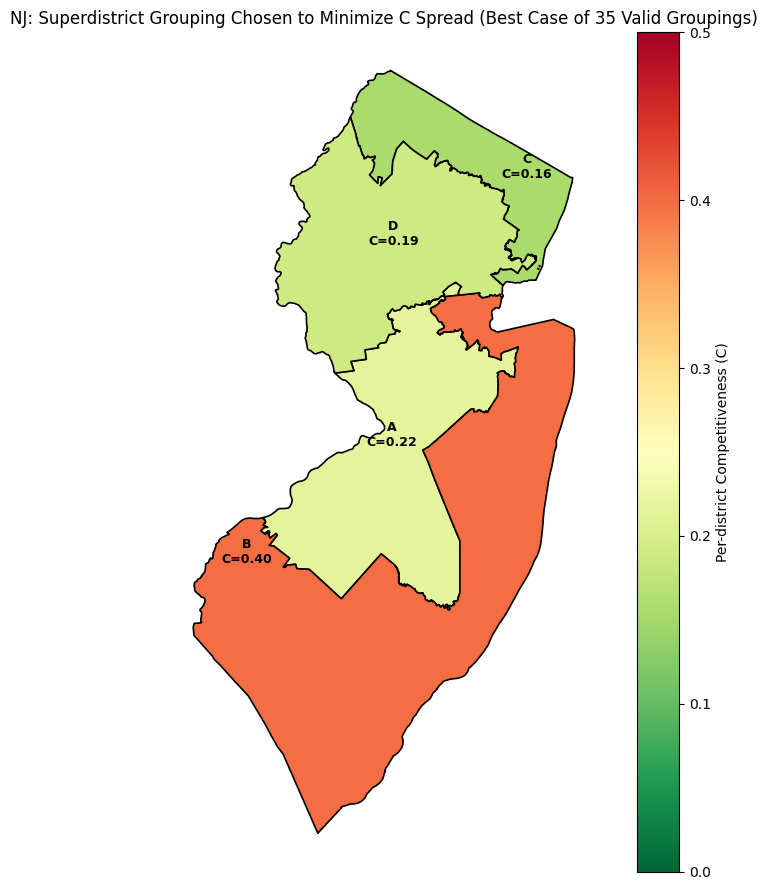

In [16]:
# NJ Map 6: 4 Superdistricts, Grouping SELECTED TO MINIMIZE SPREAD Across Superdistricts
#
# Unlike Maps 2/4/5 (each a single independently-chosen regional grouping), this cell enumerates
# EVERY geometrically valid way to partition NJ's 12 districts into 4 contiguous 3-district
# superdistricts (contiguity checked against the real shapefile adjacency graph, same as Map 5), then
# explicitly PICKS the one whose 4 per-district C values have the lowest standard deviation -- i.e.
# the grouping that makes competitiveness look most evenly spread across the map.
#
# LABEL FIX: these are PER-DISTRICT C values (compute_C with SIGMA_RCV, a real district-level sigma
# from the 8-state ensemble -- see the label fix noted in Map 4), directly comparable to SMD's
# per-district C on the same 0-0.5 scale. Not "single-seat" values.
#
# This is a deliberately different exercise from Maps 4/5: those used regionally-motivated groupings
# and reported whatever C values came out. This one starts from "which grouping makes competitiveness
# look most even" and searches for it. Out of 35 valid contiguous partitions, this is the best case --
# most groupings look considerably less even (see the printed comparison below). Treat this map as a
# best-case illustration of how even superdistrict competitiveness COULD look under a favorable
# grouping, not as a neutral estimate the way Map 4 was.
import itertools

adj_nj = {
    1: [2, 3], 2: [1, 3, 4, 6], 3: [1, 2, 4, 6, 12], 4: [2, 3, 6], 5: [7, 9, 11],
    6: [2, 3, 4, 7, 12], 7: [5, 6, 8, 10, 11, 12], 8: [7, 9, 10, 11], 9: [5, 8, 11],
    10: [7, 8, 11], 11: [5, 7, 8, 9, 10], 12: [3, 6, 7],
}
nj_districts = list(range(1, 13))

def is_connected(group, adj):
    group = set(group)
    seen = {next(iter(group))}
    frontier = list(seen)
    while frontier:
        cur = frontier.pop()
        for nb in adj[cur]:
            if nb in group and nb not in seen:
                seen.add(nb)
                frontier.append(nb)
    return seen == group

connected_triples = [c for c in itertools.combinations(nj_districts, 3) if is_connected(c, adj_nj)]

partitions = []
def backtrack(remaining, groups):
    if not remaining:
        partitions.append(list(groups))
        return
    first = min(remaining)
    for triple in connected_triples:
        if first in triple and set(triple).issubset(remaining):
            backtrack(remaining - set(triple), groups + [triple])
backtrack(set(nj_districts), [])

scored = []
for part in partitions:
    c_vals = [compute_C(np.mean([nj_dem_share[d] for d in g]), sigma=SIGMA_RCV) for g in part]
    scored.append({"groups": part, "C": c_vals, "std": np.std(c_vals), "mean": np.mean(c_vals)})
scored.sort(key=lambda r: r["std"])

print(f"{len(partitions)} geometrically valid contiguous 4x3 groupings found.")
print(f"Std dev of the 4 per-district C values ranges from {scored[0]['std']:.4f} (most even) to {scored[-1]['std']:.4f} (least even) across all of them.")
print(f"\nMost even grouping selected:")
best = scored[0]
print(f"  groups = {best['groups']}")
print(f"  C = {[round(c, 3) for c in best['C']]}, mean = {best['mean']:.3f}, std = {best['std']:.4f}")

nj_superdistricts_v3 = {chr(ord("A") + i): list(g) for i, g in enumerate(best["groups"])}
district_to_sd_v3 = {d: sd for sd, ds in nj_superdistricts_v3.items() for d in ds}
nj_gdf["superdistrict_v3"] = nj_gdf["district"].map(district_to_sd_v3)

sd_rows_v3 = []
for name, districts in nj_superdistricts_v3.items():
    avg_share = np.mean([nj_dem_share[d] for d in districts])
    c_val = compute_C(avg_share, sigma=SIGMA_RCV)
    sd_rows_v3.append({"superdistrict": name, "districts": districts, "avg_dem_share": avg_share, "per_district_C": c_val})
sd_df_v3 = pd.DataFrame(sd_rows_v3)
print()
print(sd_df_v3.to_string(index=False))

sd_gdf_v3 = nj_gdf.dissolve(by="superdistrict_v3").reset_index().merge(
    sd_df_v3.rename(columns={"superdistrict": "superdistrict_v3"}), on="superdistrict_v3"
)

fig, ax = plt.subplots(figsize=(9, 9))
sd_gdf_v3.plot(column="per_district_C", cmap="RdYlGn_r", vmin=0, vmax=0.5, edgecolor="black", linewidth=1.2,
               legend=True, legend_kwds={"label": "Per-district Competitiveness (C)"}, ax=ax)

for _, row in sd_gdf_v3.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{row['superdistrict_v3']}\nC={row['per_district_C']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=9, fontweight="bold")

ax.set_axis_off()
ax.set_title("NJ: Superdistrict Grouping Chosen to Minimize C Spread (Best Case of 35 Valid Groupings)", fontsize=12)
plt.tight_layout()
plt.show()


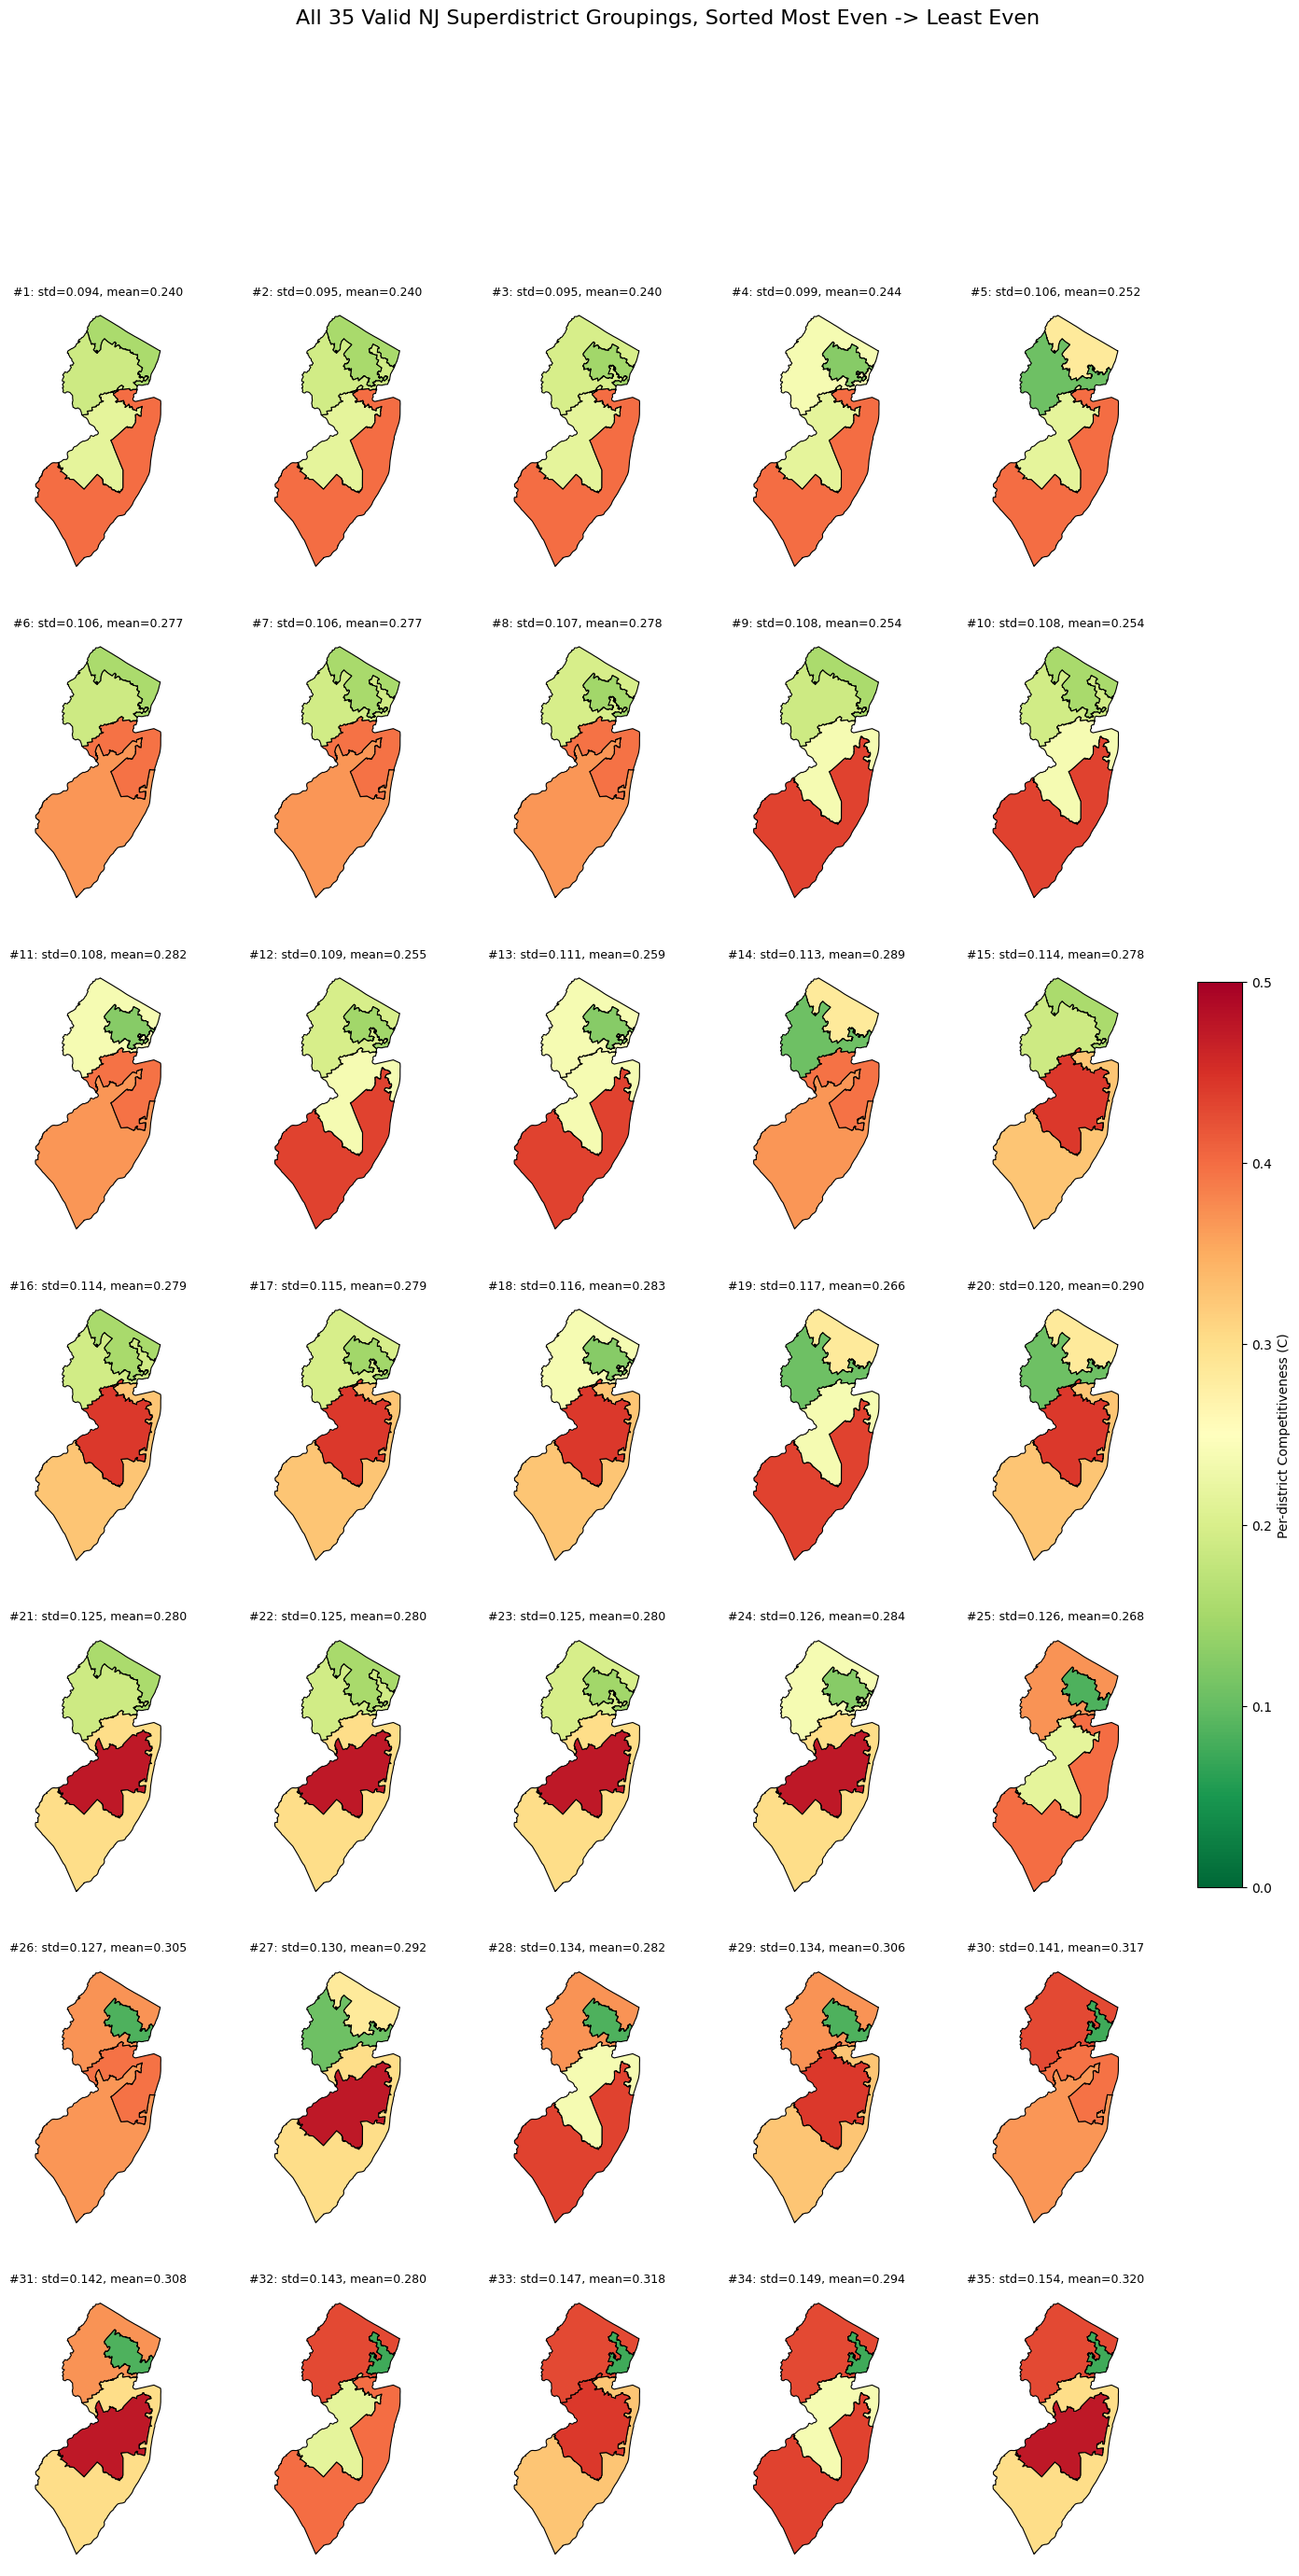

In [17]:
# NJ Map 6b: Small-Multiples of ALL 35 Geometrically Valid Superdistrict Groupings
#
# Every contiguous way to partition NJ's 12 districts into 4 three-district superdistricts (same
# `partitions`/`scored` list computed in the previous cell), sorted from most even (lowest std dev of
# the 4 per-district C values, top-left) to least even (highest std dev, bottom-right). Same color
# scale (RdYlGn_r, 0-0.5) and same direct-formula/pooled-RCV-sigma method as every other superdistrict
# map in this notebook -- only the grouping changes between panels. These are PER-DISTRICT C values
# (see the label fix noted in Map 4), not "single-seat."
import matplotlib as mpl

n = len(scored)
ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4.5 * nrows))

for idx, s in enumerate(scored):
    ax = axes.flat[idx]
    group_of = {d: gi for gi, g in enumerate(s["groups"]) for d in g}
    c_of_group = {gi: c for gi, c in enumerate(s["C"])}

    tmp = nj_gdf[["district", "geometry"]].copy()
    tmp["grp"] = tmp["district"].map(group_of)
    tmp["C_grp"] = tmp["grp"].map(c_of_group)
    dissolved = tmp.dissolve(by="grp")

    dissolved.plot(column="C_grp", cmap="RdYlGn_r", vmin=0, vmax=0.5,
                    edgecolor="black", linewidth=0.8, ax=ax)
    ax.set_axis_off()
    ax.set_title(f"#{idx+1}: std={s['std']:.3f}, mean={s['mean']:.3f}", fontsize=9)

for idx in range(n, nrows * ncols):
    axes.flat[idx].set_axis_off()

sm = mpl.cm.ScalarMappable(cmap="RdYlGn_r", norm=mpl.colors.Normalize(vmin=0, vmax=0.5))
sm.set_array([])
fig.colorbar(sm, ax=axes, shrink=0.4, label="Per-district Competitiveness (C)", location="right")

fig.suptitle(f"All {n} Valid NJ Superdistrict Groupings, Sorted Most Even -> Least Even", fontsize=16)
plt.show()


superdistrict   districts  avg_dem_share  per_seat_C  per_district_C
            A   [1, 2, 3]      53.860000    0.122934        0.368803
            B  [4, 6, 12]      53.016667    0.132022        0.396065
            C   [5, 7, 9]      53.796667    0.123604        0.370811
            D [8, 10, 11]      71.013333    0.028560        0.085679

Per-seat mean = 0.102   Per-district mean = 0.305


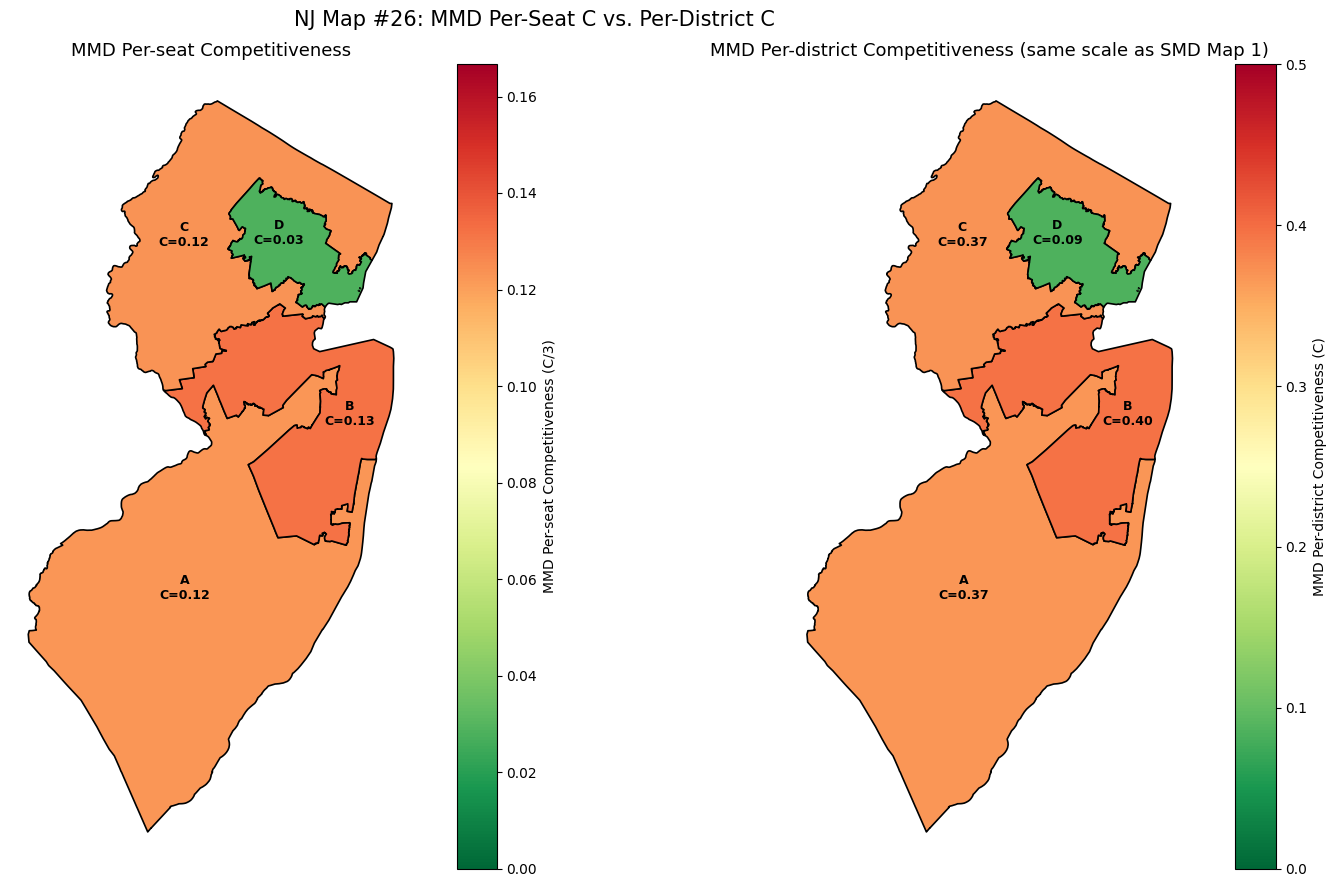

In [18]:
# NJ Map #26: MMD Per-Seat C (left) vs. MMD Per-District C (right)
#
# Grouping #26: {1,2,3}, {4,6,12}, {5,7,9}, {8,10,11}.
#
# Per-district C = compute_C(avg_share, sigma=SIGMA_RCV) -- the real, ensemble-grounded quantity
# (SIGMA_RCV is a genuine district-level sigma from the 8-state RCV ensemble; see the label fix
# earlier in this notebook). This is directly comparable to SMD's per-district C on the same 0-0.5
# scale.
#
# Per-seat C = per-district C / 3 -- the "3xC" relationship, applied in reverse now that we know
# per-district is the real/base quantity: it spreads the district's aggregate competitiveness evenly
# across its 3 seats. This is a naive decomposition (real STV seats aren't independent or equal
# slices of the district's competitiveness), not a separately-measured per-seat quantity -- there
# isn't one, since real multi-winner RCV has no separable per-seat vote share (see the last message's
# explanation of why one ballot can affect multiple seats' outcomes via transfers).
sel = scored[25]  # rank #26 (0-indexed) by per-district-C evenness
nj_superdistricts_26 = {chr(ord("A") + i): list(g) for i, g in enumerate(sel["groups"])}
district_to_sd_26 = {d: sd for sd, ds in nj_superdistricts_26.items() for d in ds}
nj_gdf["superdistrict_26"] = nj_gdf["district"].map(district_to_sd_26)

sd_rows_26 = []
for name, districts in nj_superdistricts_26.items():
    avg_share = np.mean([nj_dem_share[d] for d in districts])
    per_district_C = compute_C(avg_share, sigma=SIGMA_RCV)
    per_seat_C = per_district_C / 3
    sd_rows_26.append({
        "superdistrict": name, "districts": districts, "avg_dem_share": avg_share,
        "per_seat_C": per_seat_C, "per_district_C": per_district_C,
    })
sd_df_26 = pd.DataFrame(sd_rows_26)
print(sd_df_26.to_string(index=False))
print(f"\nPer-seat mean = {sd_df_26['per_seat_C'].mean():.3f}   Per-district mean = {sd_df_26['per_district_C'].mean():.3f}")

sd_gdf_26 = nj_gdf.dissolve(by="superdistrict_26").reset_index().merge(
    sd_df_26.rename(columns={"superdistrict": "superdistrict_26"}), on="superdistrict_26"
)

PALETTE = "RdYlGn_r"
SEAT_VMAX = 0.5 / 3

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 9))

sd_gdf_26.plot(column="per_seat_C", cmap=PALETTE, vmin=0, vmax=SEAT_VMAX, edgecolor="black", linewidth=1.2,
               legend=True, legend_kwds={"label": "MMD Per-seat Competitiveness (C/3)"}, ax=ax1)
for _, row in sd_gdf_26.iterrows():
    pt = row.geometry.representative_point()
    ax1.annotate(f"{row['superdistrict_26']}\nC={row['per_seat_C']:.2f}", (pt.x, pt.y),
                 ha="center", fontsize=9, fontweight="bold")
ax1.set_axis_off()
ax1.set_title("MMD Per-seat Competitiveness", fontsize=13)

sd_gdf_26.plot(column="per_district_C", cmap=PALETTE, vmin=0, vmax=0.5, edgecolor="black", linewidth=1.2,
               legend=True, legend_kwds={"label": "MMD Per-district Competitiveness (C)"}, ax=ax2)
for _, row in sd_gdf_26.iterrows():
    pt = row.geometry.representative_point()
    ax2.annotate(f"{row['superdistrict_26']}\nC={row['per_district_C']:.2f}", (pt.x, pt.y),
                 ha="center", fontsize=9, fontweight="bold")
ax2.set_axis_off()
ax2.set_title("MMD Per-district Competitiveness (same scale as SMD Map 1)", fontsize=13)

fig.suptitle("NJ Map #26: MMD Per-Seat C vs. Per-District C", fontsize=15)
plt.tight_layout()
plt.show()


 superdistrict  avg_dem_share  per_district_C  3C_uncapped_alt_framing  P_atleast1_alt_framing
             1      53.860000        0.261586                 0.784757                0.597375
             2      53.016667        0.261586                 0.784757                0.597375
             3      52.070000        0.261586                 0.784757                0.597375
             4      72.740000        0.171013                 0.513040                0.430305


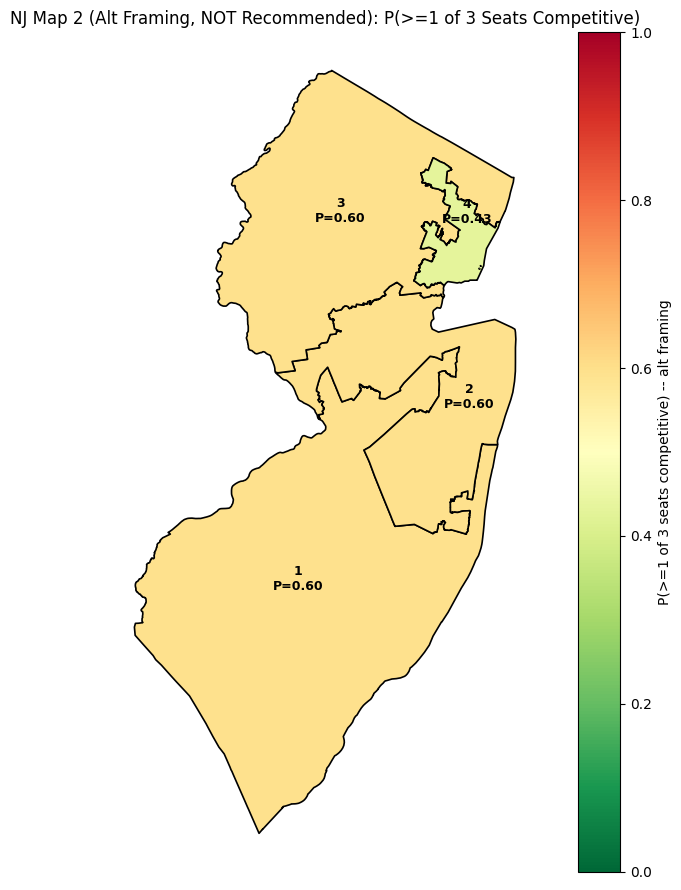

In [19]:
# NJ Map 2 (Alternative Framing): P(>=1 of 3 Seats Competitive) = 1-(1-C)^3
#
# CORRECTION / IMPORTANT CAVEAT: `sd_df["per_district_C"]` (renamed from "single_seat_C" -- see the
# label fix in Map 2/4) is ALREADY the real per-district competitiveness for this superdistrict,
# directly comparable to SMD's per-district C. It was never actually a "single seat" value.
#
# This cell's "at least one of 3 seats competitive" framing treats that per-district C as if it were
# one seat's toss-up chance, then asks about combining 3 of them -- but real multi-winner RCV
# elections don't have separable per-seat vote shares (all seats in a district share one ballot
# count), so there's no real "seat 1 vs seat 2 vs seat 3" decomposition to combine in the first place.
# Kept here as an alternative/exploratory framing only, NOT as the primary or recommended
# per-district metric -- use Map 2/4/5/6's per_district_C for that.
sd_df["P_atleast1_alt_framing"] = 1 - (1 - sd_df["per_district_C"]) ** 3
sd_df["3C_uncapped_alt_framing"] = 3 * sd_df["per_district_C"]
print(sd_df[["superdistrict", "avg_dem_share", "per_district_C", "3C_uncapped_alt_framing", "P_atleast1_alt_framing"]].to_string(index=False))

sd_gdf_p = nj_gdf.dissolve(by="superdistrict").reset_index().merge(sd_df, on="superdistrict")

fig, ax = plt.subplots(figsize=(9, 9))
sd_gdf_p.plot(column="P_atleast1_alt_framing", cmap="RdYlGn_r", vmin=0, vmax=1, edgecolor="black", linewidth=1.2,
              legend=True, legend_kwds={"label": "P(>=1 of 3 seats competitive) -- alt framing"}, ax=ax)

for _, row in sd_gdf_p.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{row['superdistrict']}\nP={row['P_atleast1_alt_framing']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=9, fontweight="bold")

ax.set_axis_off()
ax.set_title("NJ Map 2 (Alt Framing, NOT Recommended): P(>=1 of 3 Seats Competitive)", fontsize=12)
plt.tight_layout()
plt.show()


35 groupings. P(>=1 of 3 competitive) [alt framing] std dev ranges from 0.1461 (most even) to 0.2551 (least even).
Most even by P: groups=[(1, 3, 12), (2, 4, 6), (5, 8, 9), (7, 10, 11)], P=[np.float64(0.518), np.float64(0.783), np.float64(0.398), np.float64(0.465)], mean=0.541
Most even by per-district C (Map 6, recommended): groups=[(1, 3, 12), (2, 4, 6), (5, 8, 9), (7, 10, 11)]


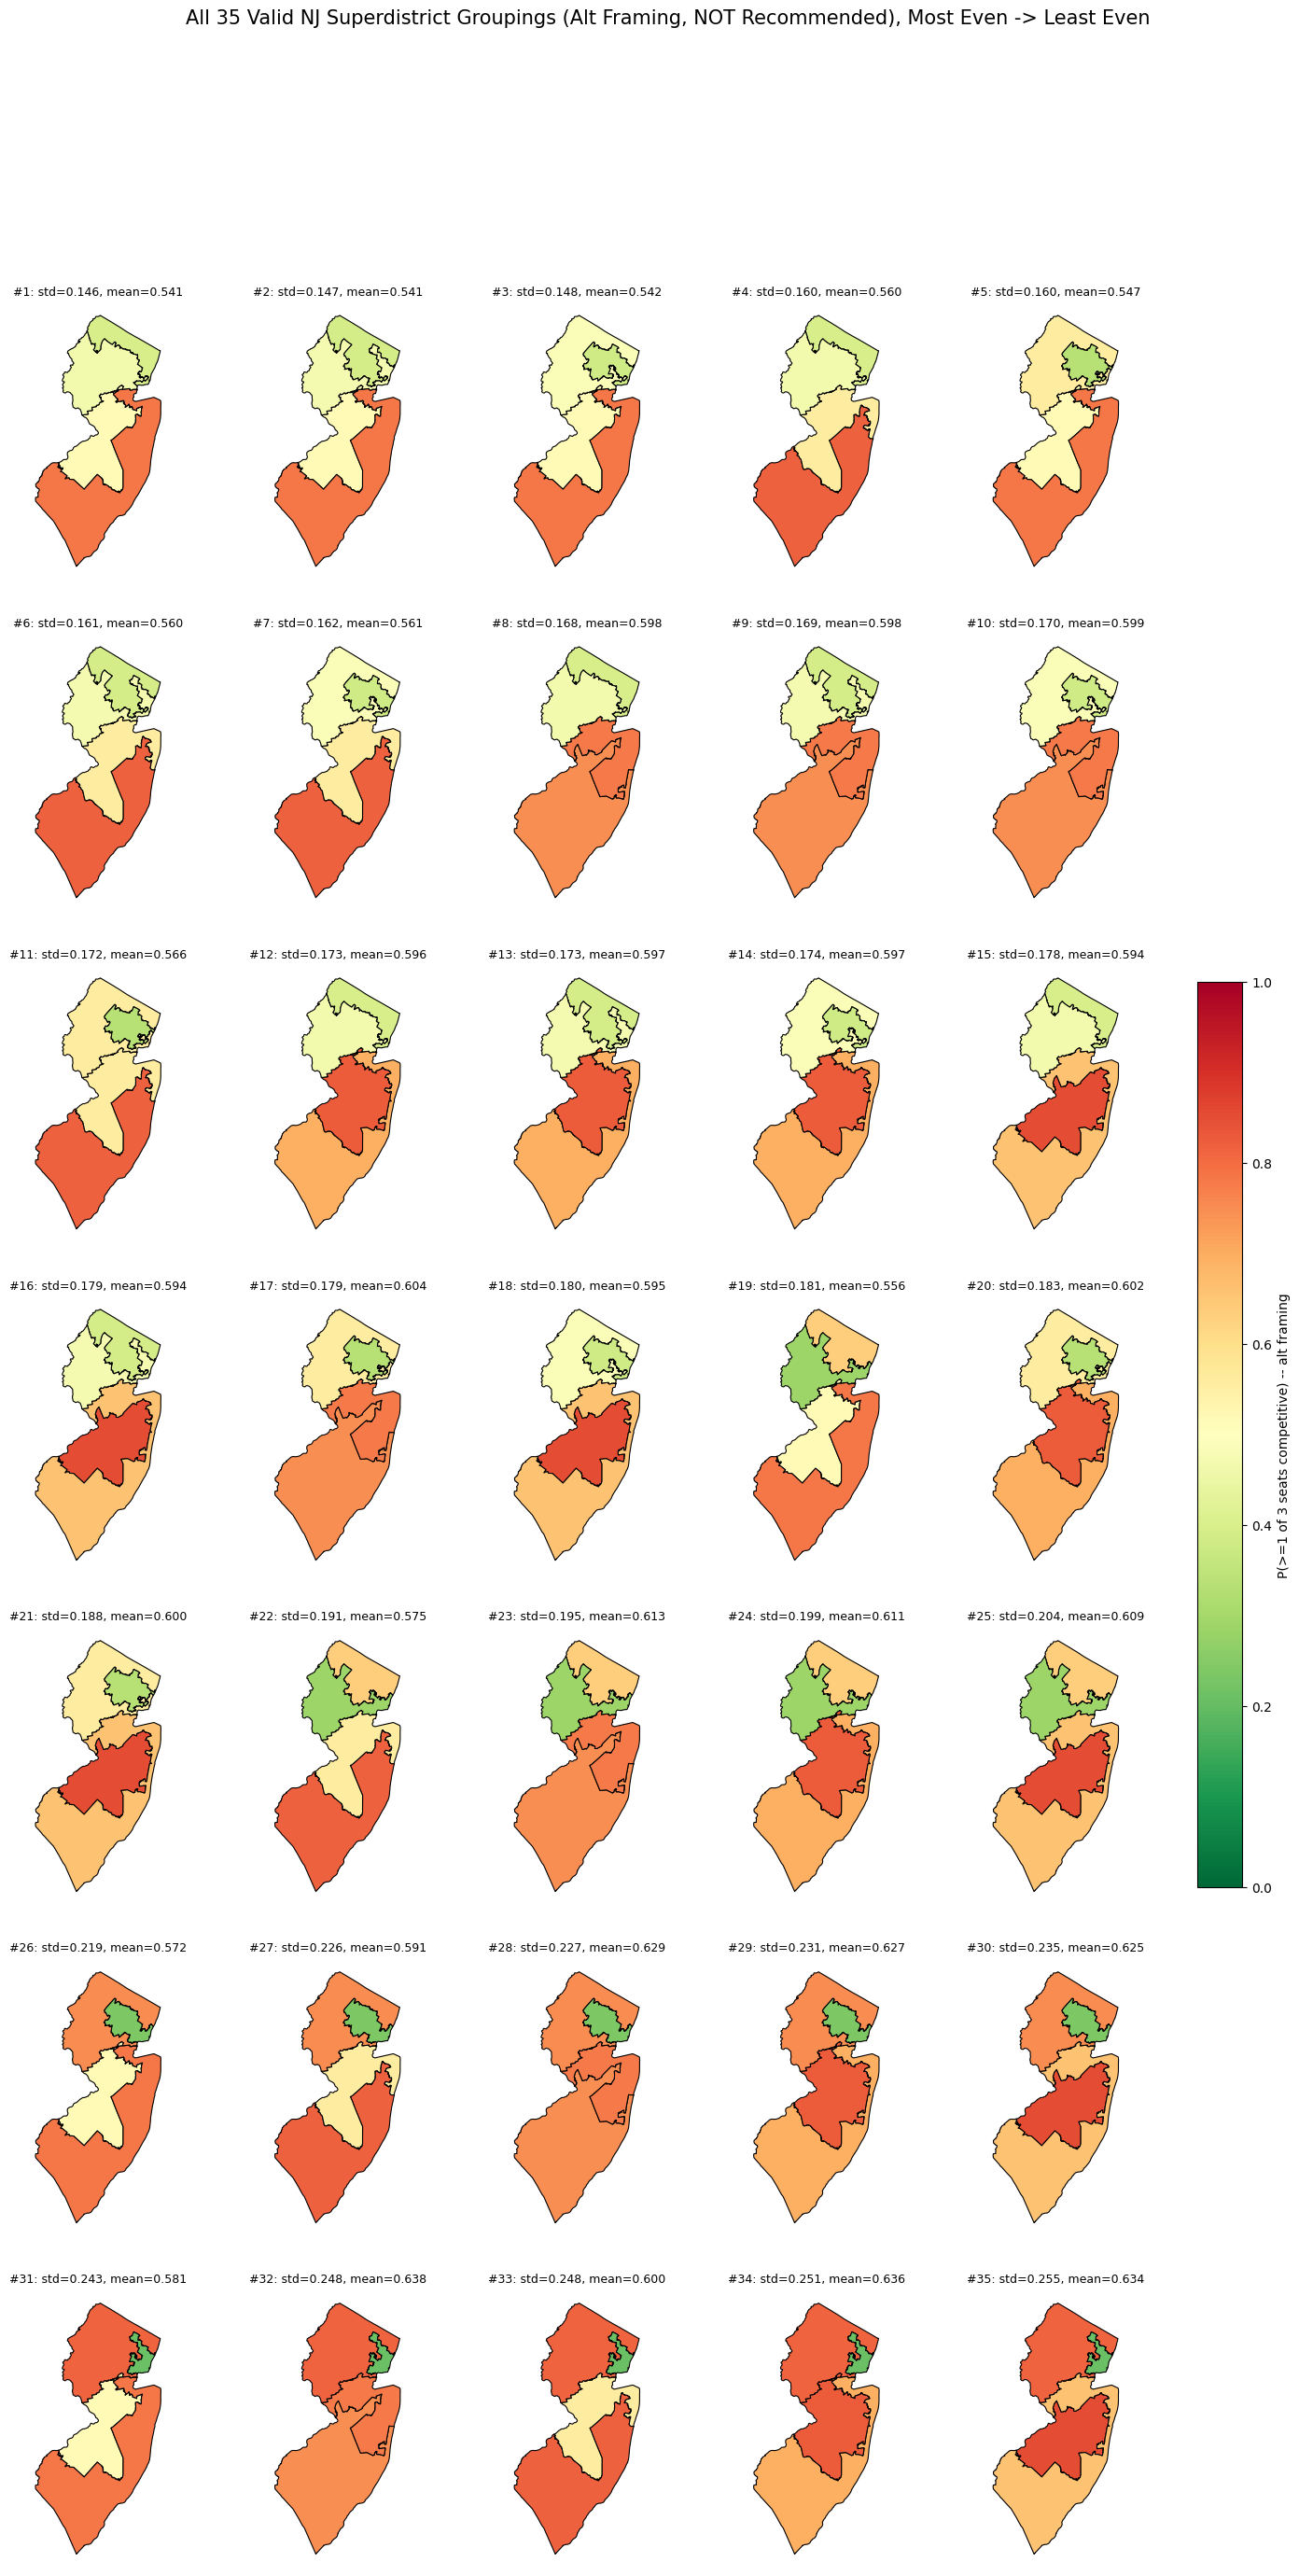

In [20]:
# NJ Map 6c (Alternative Framing): Small-Multiples of All 35 Groupings, P(>=1 of 3 Seats Competitive)
#
# CAVEAT: same as Map 2's alternative-framing cell above -- `compute_C(..., sigma=SIGMA_RCV)` already
# returns real PER-DISTRICT competitiveness (see the label fix in Map 4), not a per-seat value. This
# cell's "P(>=1 of 3 seats competitive)" treats that per-district C as if it were one seat among 3
# independent ones, which doesn't correspond to how a real multi-winner RCV contest works (no
# separable per-seat vote shares -- one shared ballot count decides all seats in a district). Kept as
# an alternative/exploratory framing only, NOT the recommended per-district metric -- use the
# Map 6/6b per_district_C grid for that.
import matplotlib as mpl

scored_p = []
for part in partitions:
    c_vals = [compute_C(np.mean([nj_dem_share[d] for d in g]), sigma=SIGMA_RCV) for g in part]
    p_vals = [1 - (1 - c) ** 3 for c in c_vals]
    scored_p.append({"groups": part, "C": c_vals, "P": p_vals, "std": np.std(p_vals), "mean": np.mean(p_vals)})
scored_p.sort(key=lambda r: r["std"])

print(f"{len(partitions)} groupings. P(>=1 of 3 competitive) [alt framing] std dev ranges from "
      f"{scored_p[0]['std']:.4f} (most even) to {scored_p[-1]['std']:.4f} (least even).")
print(f"Most even by P: groups={scored_p[0]['groups']}, P={[round(p,3) for p in scored_p[0]['P']]}, mean={scored_p[0]['mean']:.3f}")
print(f"Most even by per-district C (Map 6, recommended): groups=[(1, 3, 12), (2, 4, 6), (5, 8, 9), (7, 10, 11)]")

n = len(scored_p)
ncols = 5
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4.5 * nrows))

for idx, s in enumerate(scored_p):
    ax = axes.flat[idx]
    group_of = {d: gi for gi, g in enumerate(s["groups"]) for d in g}
    p_of_group = {gi: p for gi, p in enumerate(s["P"])}

    tmp = nj_gdf[["district", "geometry"]].copy()
    tmp["grp"] = tmp["district"].map(group_of)
    tmp["P_grp"] = tmp["grp"].map(p_of_group)
    dissolved = tmp.dissolve(by="grp")

    dissolved.plot(column="P_grp", cmap="RdYlGn_r", vmin=0, vmax=1,
                    edgecolor="black", linewidth=0.8, ax=ax)
    ax.set_axis_off()
    ax.set_title(f"#{idx+1}: std={s['std']:.3f}, mean={s['mean']:.3f}", fontsize=9)

for idx in range(n, nrows * ncols):
    axes.flat[idx].set_axis_off()

sm = mpl.cm.ScalarMappable(cmap="RdYlGn_r", norm=mpl.colors.Normalize(vmin=0, vmax=1))
sm.set_array([])
fig.colorbar(sm, ax=axes, shrink=0.4, label="P(>=1 of 3 seats competitive) -- alt framing", location="right")

fig.suptitle(f"All {n} Valid NJ Superdistrict Groupings (Alt Framing, NOT Recommended), Most Even -> Least Even", fontsize=15)
plt.show()


 district  dem_vote_share        C
        1          0.8125 0.077212
        2          0.7931 0.054708
        3          0.5693 0.332492
        4          0.5644 0.329560
        5          0.6553 0.171276
        6          0.8440 0.046314
        7          0.3999 0.179918
        8          0.4483 0.365615
        9          0.5187 0.446735
       10          0.5629 0.308137
       11          0.5431 0.376634
       12          0.5491 0.381789
       13          0.7044 0.132456
       14          0.2991 0.141739
       15          0.4843 0.433797
       16          0.5325 0.420686
       17          0.4369 0.356244
       18          0.5725 0.320904
       19          0.7509 0.113724
       20          0.7195 0.116883
       21          0.3932 0.264571

Step 0: mean C = 0.256, sum = 5.371


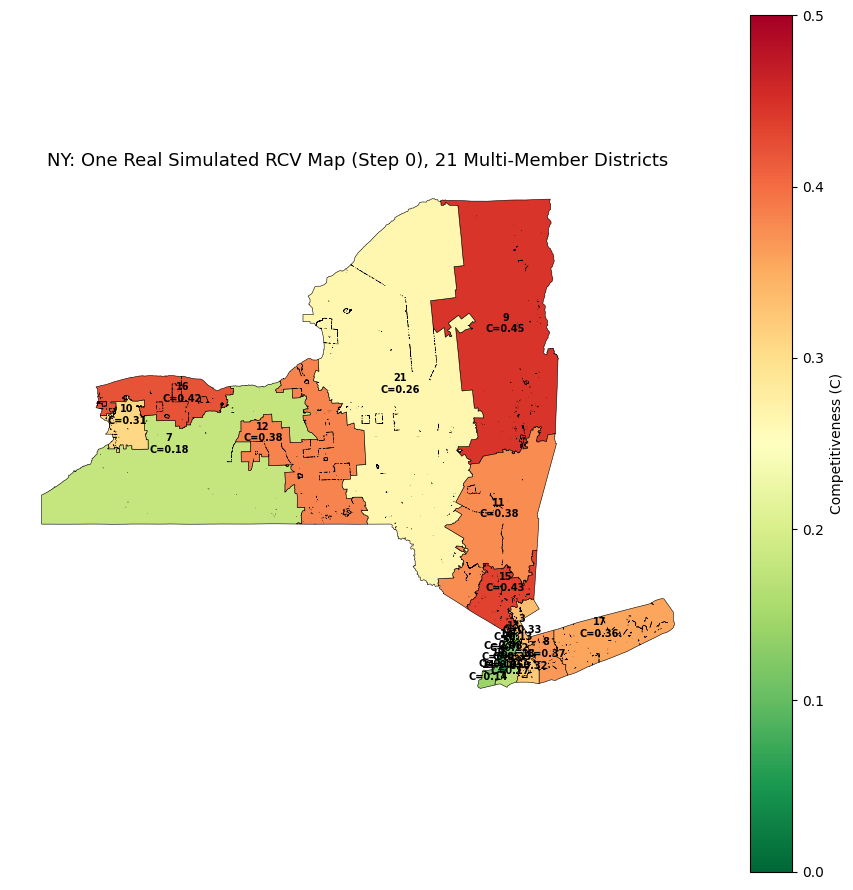

In [21]:
# NY Map: One Real Simulated RCV Map (21 Multi-Member Districts), Colored by That Map's Actual C
#
# Unlike the NJ maps, NY is one of this project's own 8 ensemble states -- no borrowing, no pooled
# sigma, no bin lookup needed. We have NY's real precinct geometry (ny_2024_gen_all_prec_updated.shp,
# 13402 precincts) and the real precinct-to-district assignment for each of the 100 simulated RCV
# maps (NY_sl_sampled_maps_assignments_p.pkl). This draws ONE of those simulated maps (step 0) by
# dissolving precincts into their assigned district, colored by that exact map/step's actual
# simulated C from election_margins_rcv[NY] -- a real result, not an approximation.
#
# Caveat: NY's SMD (63-district) ensemble only has aggregate stats saved to disk (seat shares,
# margins) -- the actual precinct-to-district assignments for those maps were never persisted, so
# there's no equivalent SMD map to draw here without rerunning that half of the simulation.
import json
from shapely.geometry import shape
from shapely.ops import unary_union

with open("/Users/zhaoyiran/Desktop/Data/NY/NY_sl_sampled_maps_assignments_p.pkl", "rb") as f:
    ny_assignments = pickle.load(f)

ny_prec_gdf = gpd.read_file("/Users/zhaoyiran/Desktop/Data/NY/ny_2024_gen_prec/ny_2024_gen_all_prec/ny_2024_gen_all_prec_updated.shp")

STEP = 0
step0_assignment = ny_assignments[STEP]  # {precinct_row_index: district_number}
ny_prec_gdf["district"] = ny_prec_gdf.index.map(step0_assignment)

ny_districts_gdf = ny_prec_gdf.dissolve(by="district").reset_index()

ny_step0_C = election_margins_rcv["NY"][election_margins_rcv["NY"]["step"] == STEP].set_index("district")["C"]
ny_step0_vs = election_margins_rcv["NY"][election_margins_rcv["NY"]["step"] == STEP].set_index("district")["dem_vote_share"]
ny_districts_gdf["C"] = ny_districts_gdf["district"].map(ny_step0_C)
ny_districts_gdf["dem_vote_share"] = ny_districts_gdf["district"].map(ny_step0_vs)

print(ny_districts_gdf[["district", "dem_vote_share", "C"]].sort_values("district").to_string(index=False))
print(f"\nStep {STEP}: mean C = {ny_districts_gdf['C'].mean():.3f}, sum = {ny_districts_gdf['C'].sum():.3f}")

fig, ax = plt.subplots(figsize=(9, 9))
ny_districts_gdf.plot(column="C", cmap="RdYlGn_r", vmin=0, vmax=0.5, edgecolor="black", linewidth=0.4,
                       legend=True, legend_kwds={"label": "Competitiveness (C)"}, ax=ax)

for _, row in ny_districts_gdf.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{int(row['district'])}\nC={row['C']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=7, fontweight="bold")

ax.set_axis_off()
ax.set_title(f"NY: One Real Simulated RCV Map (Step {STEP}), 21 Multi-Member Districts", fontsize=13)
plt.tight_layout()
plt.show()


 district  dem_share        C
        1  46.045996 0.406601
        2  45.218180 0.387948
        3  52.267688 0.445796
        4  53.843829 0.409116
        5  80.701578 0.086021
        6  64.052090 0.220049
        7  82.079288 0.080439
        8  78.225400 0.097452
        9  76.784274 0.105056
       10  85.587045 0.068299
       11  43.857172 0.358349
       12  84.102876 0.073103
       13  90.816327 0.054487
       14  77.961655 0.098787
       15  86.961337 0.064232
       16  70.003024 0.153373
       17  53.447058 0.418233
       18  52.826944 0.432647
       19  50.704797 0.483063
       20  57.157371 0.337273
       21  40.699088 0.295853
       22  53.697880 0.412459
       23  39.129555 0.268365
       24  37.639424 0.244521
       25  57.709520 0.326189
       26  61.307295 0.261148

Real NY SMDs (DRA composite, pooled SMD sigma): mean C = 0.253, sum = 6.589


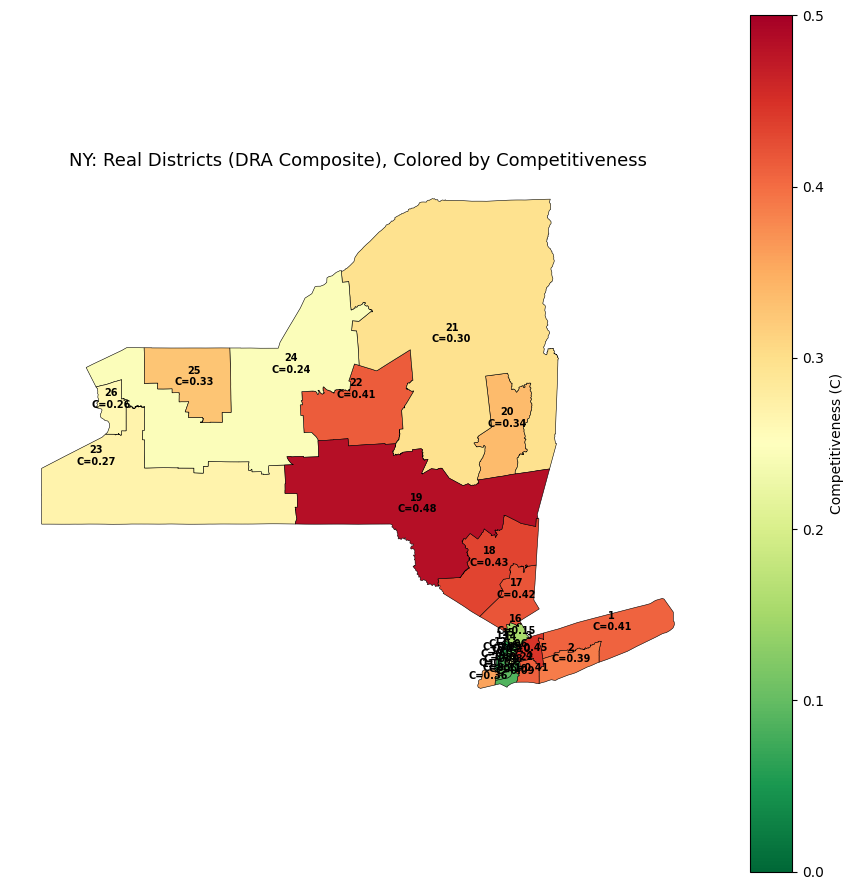

In [22]:
# NY Map 1: Actual 26 SMDs, Colored by CURRENT (DRA Composite) Competitiveness
#
# NOT simulated -- these are NY's real, currently-used single-member districts (118th/119th Congress
# boundaries, Census TIGER tl_2023_36_cd118, unchanged since the 2022 court-ordered map). Dem/Rep
# share here is Dave's Redistricting App's composite partisan index per district, user-provided from
# a manual DRA export (NY-2024-Congressional-district-statistics.csv) -- same source/vintage as the
# NJ maps, rather than a single election's raw results, so this NY map is directly comparable to the
# NJ ones on methodology.
#
# NOTE: the CSV has a trailing comma on every data row, which -- with pd.read_csv's default
# behavior -- silently shifts every column over by one and demotes the real "ID" to the row index
# (so "Dem"/"Rep" end up holding the real Rep/Oth columns instead). index_col=False disables that
# shift and keeps every column aligned with its header name.
#
# Same formula as everywhere else in this notebook: C = min(p, 1-p), p = t_dist.cdf(t, df=2),
# t = M/sigma, M = dem_frac - 0.5. sigma = SMD ensemble's real pooled mean sigma (SIGMA, computed
# above in the NJ Map 1 cell).
ny_dra = pd.read_csv("/Users/zhaoyiran/Desktop/Data/NY/NY-2024-Congressional-district-statistics.csv", index_col=False)
ny_dra = ny_dra[ny_dra["ID"].astype(str).str.strip().str.isnumeric()].copy()
ny_dra["district"] = ny_dra["ID"].astype(int)
ny_dra["dem_share"] = ny_dra["Dem"] / (ny_dra["Dem"] + ny_dra["Rep"]) * 100
ny_dem_share = ny_dra.set_index("district")["dem_share"].to_dict()

ny_gdf = gpd.read_file("/Users/zhaoyiran/Desktop/Data/NY/tl_2023_36_cd118/tl_2023_36_cd118.shp")
ny_gdf["district"] = ny_gdf["CD118FP"].astype(int)
ny_gdf["dem_share"] = ny_gdf["district"].map(ny_dem_share)
ny_gdf["C"] = ny_gdf["dem_share"].apply(compute_C)

print(ny_gdf[["district", "dem_share", "C"]].sort_values("district").to_string(index=False))
print(f"\nReal NY SMDs (DRA composite, pooled SMD sigma): mean C = {ny_gdf['C'].mean():.3f}, sum = {ny_gdf['C'].sum():.3f}")

fig, ax = plt.subplots(figsize=(9, 9))
ny_gdf.plot(column="C", cmap="RdYlGn_r", vmin=0, vmax=0.5, edgecolor="black", linewidth=0.4,
            legend=True, legend_kwds={"label": "Competitiveness (C)"}, ax=ax)

for _, row in ny_gdf.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{row['district']}\nC={row['C']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=7, fontweight="bold")

ax.set_axis_off()
ax.set_title("NY: Real Districts (DRA Composite), Colored by Competitiveness", fontsize=13)
plt.tight_layout()
plt.show()


superdistrict  n_seats        districts  avg_dem_share  single_seat_C
           LI        4     [1, 2, 3, 4]      49.343923       0.476916
           Q1        3       [8, 9, 11]      66.288949       0.123052
           Q2        3      [7, 10, 12]      83.923069       0.038755
           Q3        3       [5, 6, 14]      74.238441       0.068547
           Q4        3     [13, 15, 16]      82.593563       0.041589
           HV        3     [17, 18, 19]      52.326266       0.419141
          CAP        3     [20, 21, 22]      50.518113       0.481763
          WNY        4 [23, 24, 25, 26]      48.946448       0.462993

Map 1 (26 real SMDs, pooled SMD sigma):   mean C = 0.253, sum = 6.589
Map 2 (8 superdistricts, pooled RCV sigma): mean C = 0.264, sum = 2.113


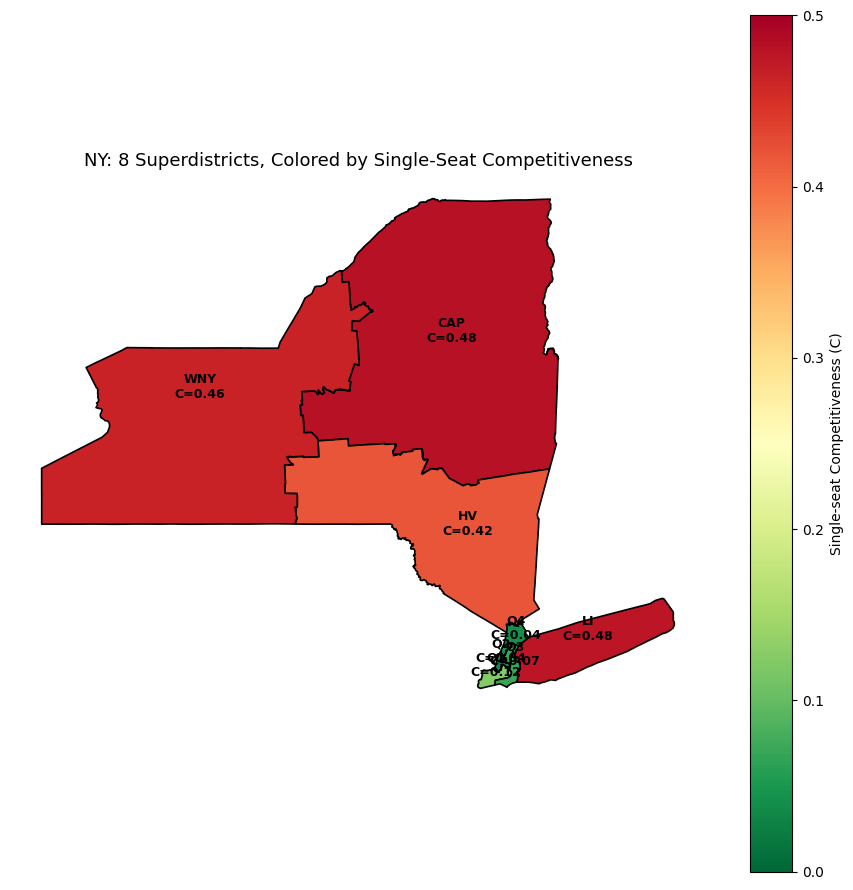

In [23]:
# NY Map 2: 8 Superdistricts (Multi-Winner MMD), Colored by Directly-Computed Competitiveness (RCV sigma)
#
# NY's 26 real districts grouped into 8 geographically contiguous superdistricts (six 3-member, two
# 4-member -- 26 doesn't divide evenly by 3 the way NJ's 12 did). Grouping is MY OWN regional
# approximation (Long Island / NYC boroughs split four ways / Hudson Valley / Capital-North Country /
# Western NY) -- not an official DRA proposal. Contiguity verified programmatically against the real
# shapefile's adjacency graph (districts sharing a border via .touches()/.intersects()), same method
# as NJ Map 5 -- every group is a single connected component, not just "looks close on a map."
#
# Same formula/method as NJ Map 4/5: C = min(p, 1-p), p = t_dist.cdf(t, df=2), t = M/sigma, using ONE
# pooled sigma from the RCV (multi-member) ensemble (SIGMA_RCV, computed above in the NJ Map 4 cell)
# applied to each superdistrict's average DRA composite Dem share.
ny_superdistricts = {
    "LI":  [1, 2, 3, 4],          # Long Island (Suffolk/Nassau)
    "Q1":  [8, 9, 11],            # NYC (Brooklyn/Queens)
    "Q2":  [7, 10, 12],           # NYC (Queens/Bronx)
    "Q3":  [5, 6, 14],            # NYC (Bronx/Manhattan)
    "Q4":  [13, 15, 16],          # NYC (Brooklyn/Staten Island/Westchester)
    "HV":  [17, 18, 19],          # Hudson Valley
    "CAP": [20, 21, 22],          # Capital Region / North Country
    "WNY": [23, 24, 25, 26],      # Central / Western NY
}
district_to_sd = {d: sd for sd, ds in ny_superdistricts.items() for d in ds}
ny_gdf["superdistrict"] = ny_gdf["district"].map(district_to_sd)

sd_rows = []
for name, districts in ny_superdistricts.items():
    avg_share = np.mean([ny_dem_share[d] for d in districts])
    c_val = compute_C(avg_share, sigma=SIGMA_RCV)
    sd_rows.append({"superdistrict": name, "n_seats": len(districts), "districts": districts,
                     "avg_dem_share": avg_share, "single_seat_C": c_val})
sd_df_ny = pd.DataFrame(sd_rows)
print(sd_df_ny.to_string(index=False))
print(f"\nMap 1 (26 real SMDs, pooled SMD sigma):   mean C = {ny_gdf['C'].mean():.3f}, sum = {ny_gdf['C'].sum():.3f}")
print(f"Map 2 (8 superdistricts, pooled RCV sigma): mean C = {sd_df_ny['single_seat_C'].mean():.3f}, sum = {sd_df_ny['single_seat_C'].sum():.3f}")

sd_gdf_ny = ny_gdf.dissolve(by="superdistrict").reset_index().merge(sd_df_ny, on="superdistrict")

fig, ax = plt.subplots(figsize=(9, 9))
sd_gdf_ny.plot(column="single_seat_C", cmap="RdYlGn_r", vmin=0, vmax=0.5, edgecolor="black", linewidth=1.2,
               legend=True, legend_kwds={"label": "Single-seat Competitiveness (C)"}, ax=ax)

for _, row in sd_gdf_ny.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(f"{row['superdistrict']}\nC={row['single_seat_C']:.2f}", (pt.x, pt.y),
                ha="center", fontsize=9, fontweight="bold")

ax.set_axis_off()
ax.set_title("NY: 8 Superdistricts, Colored by Single-Seat Competitiveness", fontsize=13)
plt.tight_layout()
plt.show()


superdistrict   districts  per_seat_C  per_district_C
            A   [1, 2, 3]    0.358787        1.076360
            B  [4, 6, 12]    0.256910        0.770730
            C   [5, 7, 9]    0.366547        1.099641
            D [8, 10, 11]    0.187546        0.562637

Per-seat mean = 0.292   Per-district mean = 0.877


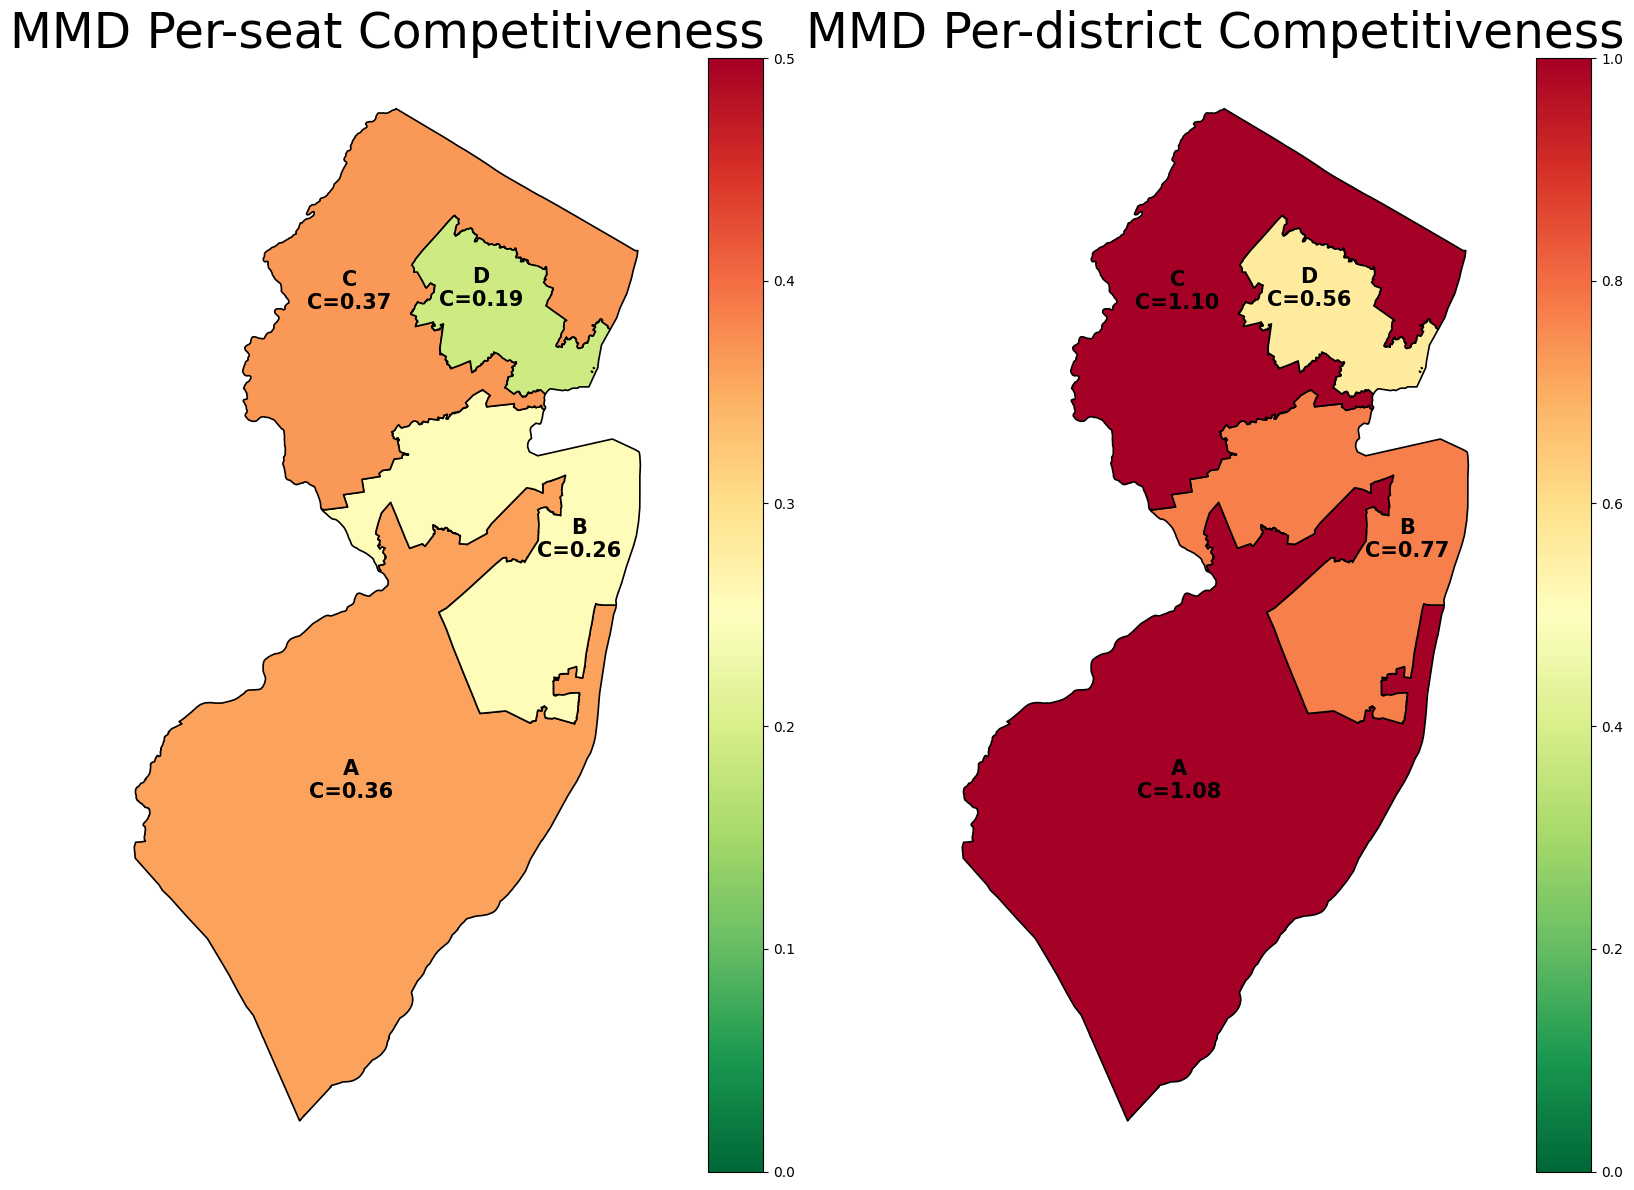

In [24]:
# NJ Map #26: MMD Per-Seat C (avg of combined SMD C) on left, MMD Per-District C (3x that) on right
#
# Grouping #26: {1,2,3}, {4,6,12}, {5,7,9}, {8,10,11}.
#
# Per-seat C = plain average of the SMD per-district C (from Map 1: nj_gdf["C"], pooled SMD sigma)
# across the 3 original districts folded into each superdistrict -- i.e. "how competitive were these
# 3 districts individually, on average, before combining them."
# Per-district C = 3x that average.
#
# This is a different (simpler) construction than the earlier version of this cell: instead of
# averaging vote SHARES and then computing one C from the combined share (which is what
# compute_C(avg_share, sigma=SIGMA_RCV) did), this averages the C VALUES themselves, computed
# per-district under SMD assumptions, then multiplies by 3 for the district-level number.
smd_C_by_district = nj_gdf.set_index("district")["C"].to_dict()

sel = scored[25]  # rank #26 (0-indexed) grouping: {1,2,3},{4,6,12},{5,7,9},{8,10,11}
nj_superdistricts_26 = {chr(ord("A") + i): list(g) for i, g in enumerate(sel["groups"])}
district_to_sd_26 = {d: sd for sd, ds in nj_superdistricts_26.items() for d in ds}
nj_gdf["superdistrict_26"] = nj_gdf["district"].map(district_to_sd_26)

sd_rows_26 = []
for name, districts in nj_superdistricts_26.items():
    per_seat_C = np.mean([smd_C_by_district[d] for d in districts])
    per_district_C = 3 * per_seat_C
    sd_rows_26.append({
        "superdistrict": name, "districts": districts,
        "per_seat_C": per_seat_C, "per_district_C": per_district_C,
    })
sd_df_26 = pd.DataFrame(sd_rows_26)
print(sd_df_26.to_string(index=False))
print(f"\nPer-seat mean = {sd_df_26['per_seat_C'].mean():.3f}   Per-district mean = {sd_df_26['per_district_C'].mean():.3f}")

sd_gdf_26 = nj_gdf.dissolve(by="superdistrict_26").reset_index().merge(
    sd_df_26.rename(columns={"superdistrict": "superdistrict_26"}), on="superdistrict_26"
)

PALETTE = "RdYlGn_r"
DIST_VMAX = round(sd_df_26["per_district_C"].max() + 0.05, 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 12))

sd_gdf_26.plot(column="per_seat_C", cmap=PALETTE, vmin=0, vmax=0.5, edgecolor="black", linewidth=1.2,
               legend=True, ax=ax1)
for _, row in sd_gdf_26.iterrows():
    pt = row.geometry.representative_point()
    ax1.annotate(f"{row['superdistrict_26']}\nC={row['per_seat_C']:.2f}", (pt.x, pt.y),
                 ha="center", fontsize=15, fontweight="bold")
ax1.set_axis_off()
ax1.set_title("MMD Per-seat Competitiveness", fontsize=35)

sd_gdf_26.plot(column="per_district_C", cmap=PALETTE, vmin=0, vmax=1, edgecolor="black", linewidth=1.2,
               legend=True,ax=ax2)
for _, row in sd_gdf_26.iterrows():
    pt = row.geometry.representative_point()
    ax2.annotate(f"{row['superdistrict_26']}\nC={row['per_district_C']:.2f}", (pt.x, pt.y),
                 ha="center", fontsize=15, fontweight="bold")
ax2.set_axis_off()
ax2.set_title(f"MMD Per-district Competitiveness", fontsize=35)

plt.tight_layout()
plt.show()
